In [1]:
import os
import pathlib
import sys
import socket

hostname = socket.gethostname()
print(hostname)


abs_path = str(pathlib.Path(hostname).parent.absolute())
WORKDIR = abs_path[:- (len(abs_path.split('/')[-2] + abs_path.split('/')[-1])+1)]



if "mimi" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"
    FIG_DIR = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/"
if "ivan" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"
    FIG_DIR = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/"



INPUT_DATA_DIR = os.path.join(DATA_DIR, 'input')
OUTPUT_DATA_DIR = os.path.join(DATA_DIR, 'output')
UTILS_DIR = os.path.join(WORKDIR, 'utils')

sys.path.append(UTILS_DIR)

# make figure directory 
try:
    new_dir = pathlib.Path(FIG_DIR+'/snowfall_rate/')
    new_dir.mkdir(parents=True, exist_ok=True)
except OSError:
    pass




ivan.uio.no


In [2]:
# supress warnings
import warnings
warnings.filterwarnings('ignore') # don't output warnings

In [3]:
# import packages
from imports import (np, plt, xr, glob, pd, cm, set_context, curve_fit, sns)
import functions as fct



In [4]:
# reload imports
%load_ext autoreload
%autoreload 2

In [5]:
# plot cosmetics
set_context('paper', font_scale=1.5, rc={"lines.linewidth": 2})

In [6]:
# particle_vars = [
#         'aggregate',
#         'graupel',
#         'pristine'
#     ]
# var_names = np.concatenate((np.array(['wind_direction', 'air_temperature', 'wind_speed', 'precipitation', 'Ze', 'W', 'spectralWidth', 'most_common_class']), np.array(particle_vars)))

# loc = 'HATPRO_Airport_10min'

### Files to read in
- snowfall classification with associated temperature and wind
- Z-S relationships
- Geonor minuetly

summarized in "Z_S_2Tm_WD_WS_class_ANX_2023_*.nc"


In [7]:
vars_to_keep = ['Geonor', 'Matrosov_a_400', 'Bracci_a_400', 'Nakai_a_400',
       'Nakai_g_400', 'Pu_g_400', 'Matrosov_a_800', 'Bracci_a_800',
       'Nakai_a_800', 'Nakai_g_800', 'Pu_g_800', 'Matrosov_a_1000',
       'Bracci_a_1000', 'Nakai_a_1000', 'Nakai_g_1000', 'Pu_g_1000',
       'Ze_linear_sum_400', 'Ze_linear_sum_800', 'Ze_linear_sum_1000',
       'air_temperature', 'wind_direction', 'wind_speed', 'Ze_400m',
       'Ze_linear_mean_400', 'Ze_linear_mean_800', 'Ze_linear_mean_1000',
       'W_400m', 'W_800m', 'W_1000m', 'snowflake_class_name', 'fallspeed',
       'flake_Dmax', 'gan3d_mass', 'count_fallspeed', 'count_flake_Dmax',
       'count_gan3d_mass', 'delta_h', 'rate_mm_h', 'start_time',
       'Z_from_linear_sum_400', 'Z_from_linear_mean_400',
       'Matrosov_a_400_mm_h', 'Bracci_a_400_mm_h', 'Nakai_a_400_mm_h',
       'Nakai_g_400_mm_h', 'Pu_g_400_mm_h', 'Matrosov_from_ze_sum_400',
       'Z_from_linear_sum_800', 'Z_from_linear_mean_800',
       'Matrosov_a_800_mm_h', 'Bracci_a_800_mm_h', 'Nakai_a_800_mm_h',
       'Nakai_g_800_mm_h', 'Pu_g_800_mm_h', 'Matrosov_from_ze_sum_800',
       'Z_from_linear_sum_1000', 'Z_from_linear_mean_1000',
       'Matrosov_a_1000_mm_h', 'Bracci_a_1000_mm_h', 'Nakai_a_1000_mm_h',
       'Nakai_g_1000_mm_h', 'Pu_g_1000_mm_h', 'Matrosov_from_ze_sum_1000',]

psd_to_keep = ['counts', 'v_bin_m_s', 'm_bin_kg', 'N_bin_m3', 'n_per_m', 'S_m_per_h', ]

In [8]:
df = dict()
ds_psd = dict()

df['event'] = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f'Z_S_2Tm_WD_WS_class_precip_event_ANX_2023.nc'))))[vars_to_keep].to_dataframe()
ds_psd['event'] = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f'Z_S_2Tm_WD_WS_class_precip_event_ANX_2023.nc'))), concat_dim="time", combine="nested")[psd_to_keep]
df['event_offset'] = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f'Z_S_2Tm_WD_WS_class_precip_event_dt_offset_ANX_2023.nc'))))[vars_to_keep].to_dataframe()
ds_psd['event_offset'] = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f'Z_S_2Tm_WD_WS_class_precip_event_dt_offset_ANX_2023.nc'))), concat_dim="time", combine="nested")[psd_to_keep]

for dt in ['1min', '5min', '10min', '30min', '60min']:
    df[dt] = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f'Z_S_2Tm_WD_WS_class_precip_{dt}_dt_offset_ANX_2023.nc'))))[vars_to_keep].to_dataframe()
    ds_psd[dt] = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f'Z_S_2Tm_WD_WS_class_precip_{dt}_dt_offset_ANX_2023.nc'))), concat_dim="time", combine="nested")[psd_to_keep]

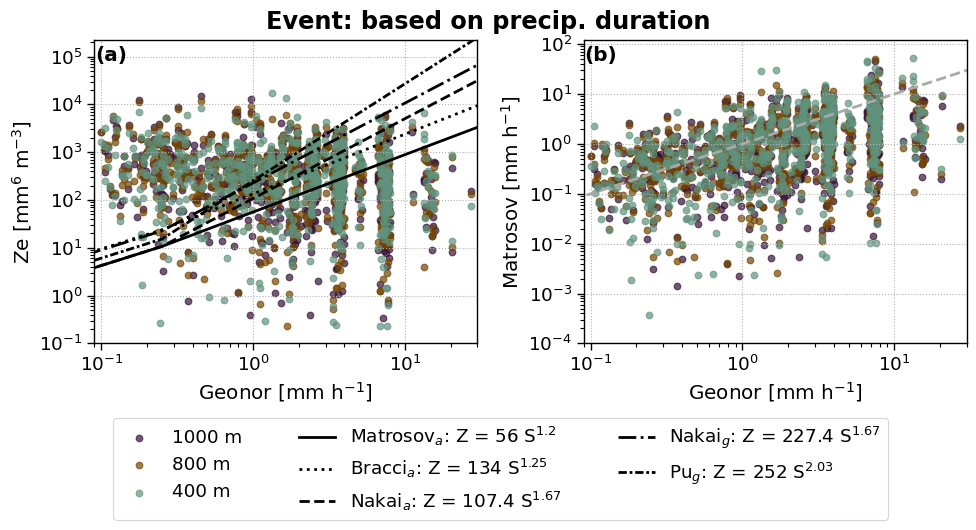

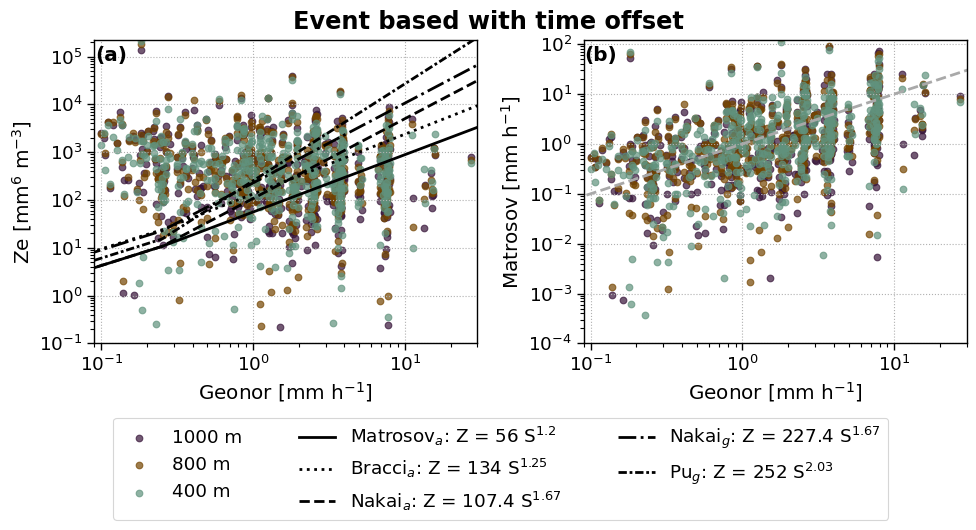

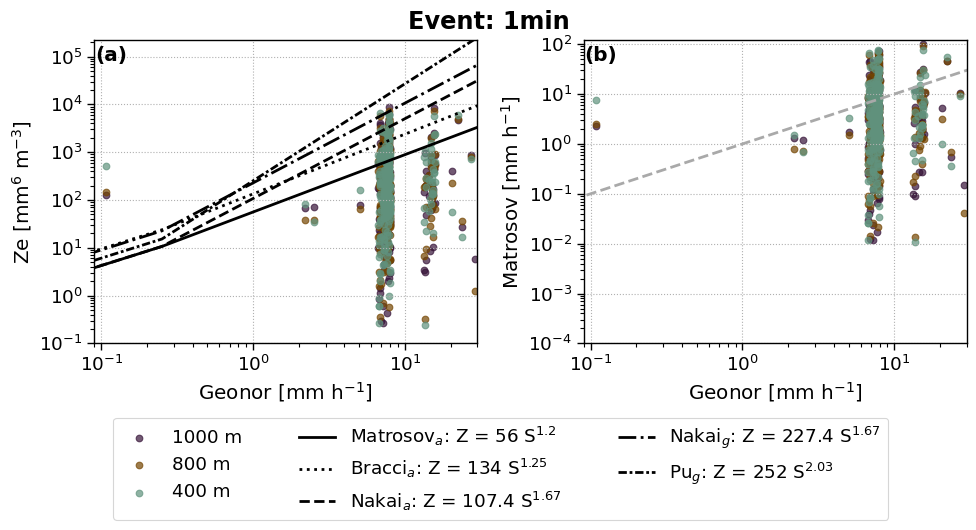

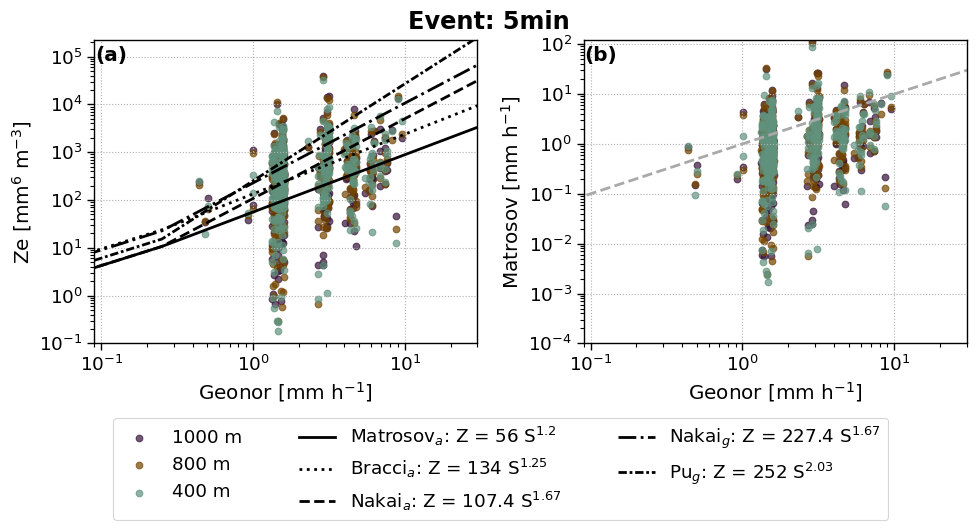

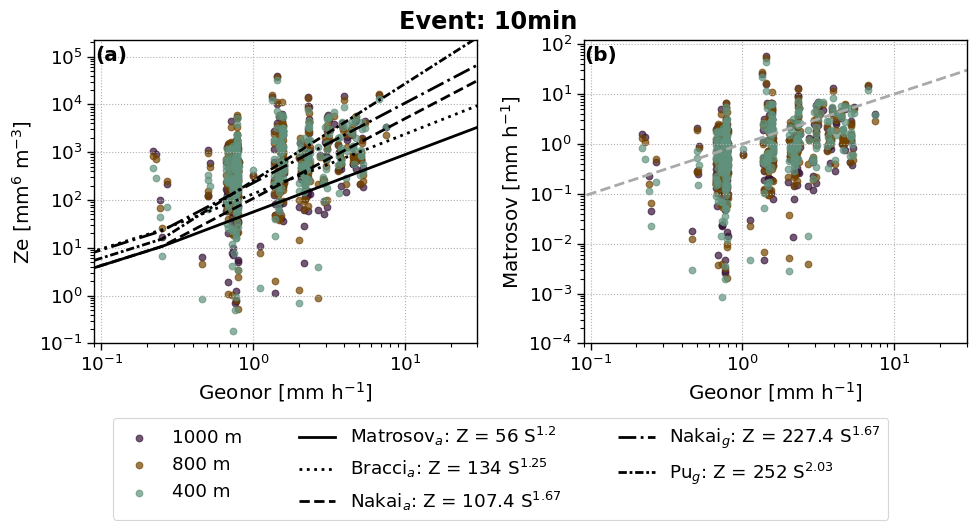

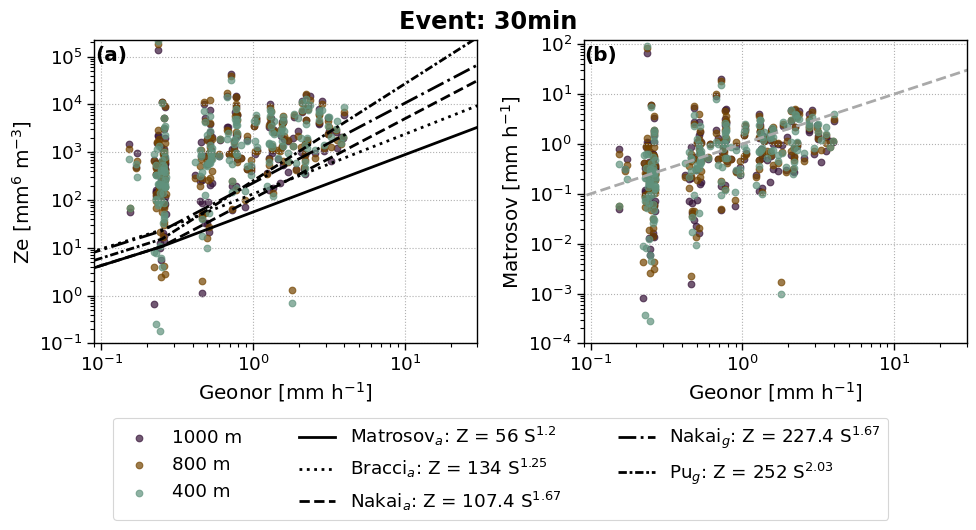

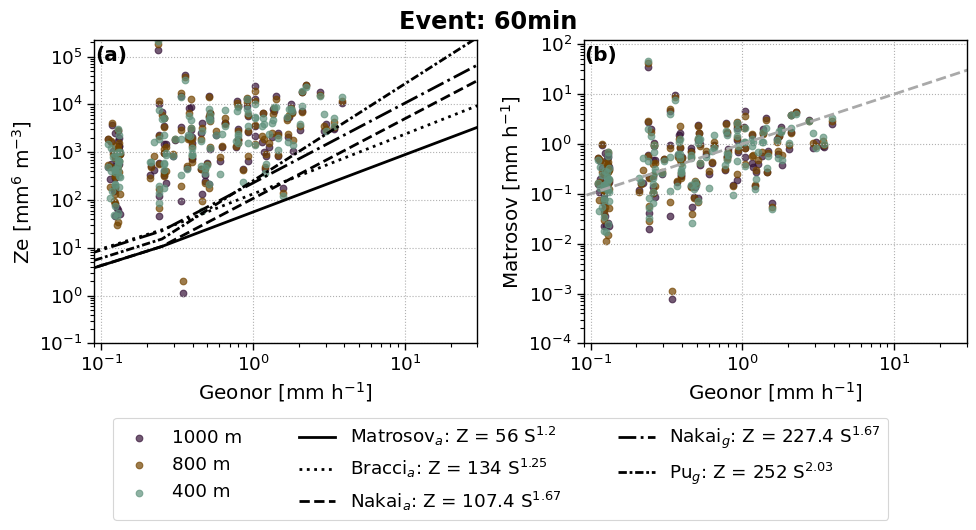

In [9]:
for dt, title in zip(df.keys(), ["Event: based on precip. duration", "Event based with time offset", "Event: 1min", "Event: 5min", "Event: 10min", "Event: 30min", "Event: 60min"]):
    fct.plt_geonor_vs_ze_vs_precip_scatter(ylabels= ['Ze [mm${^6}$ m$^{-3}]$', 'Matrosov [mm h$^{-1}$]'], class_based=False, df=df[dt], xlim=[0.09, 30],  ylim_panel0=[0.1, 220000], ylim_panel1=[0.0001, 120], title=title)

    


In [10]:
df_only_class = dict()
for duration in df.keys():
    df_only_class[duration] = dict()
    for class_name in ['aggregate', 'graupel', 'mixed', 'pristine']:
        df_only_class[duration][class_name] = df[duration][df[duration]['snowflake_class_name'] == class_name]

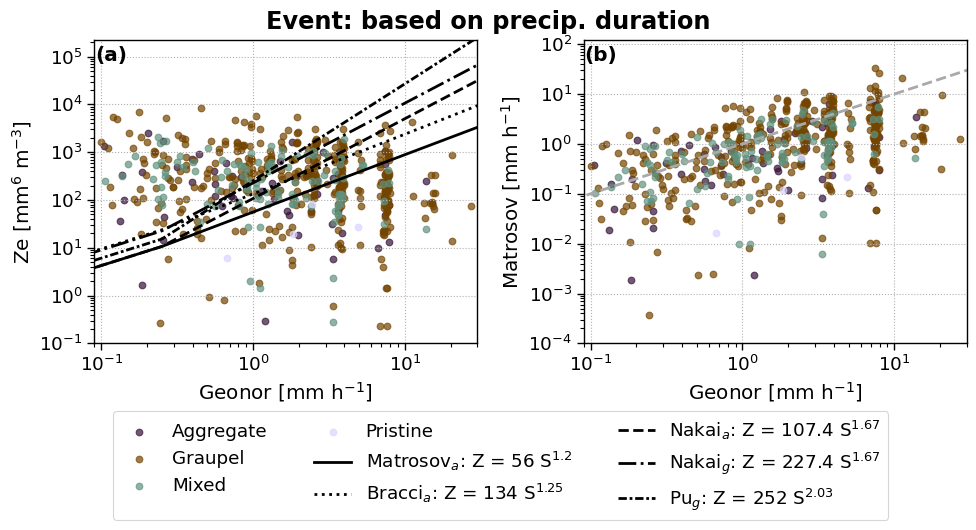

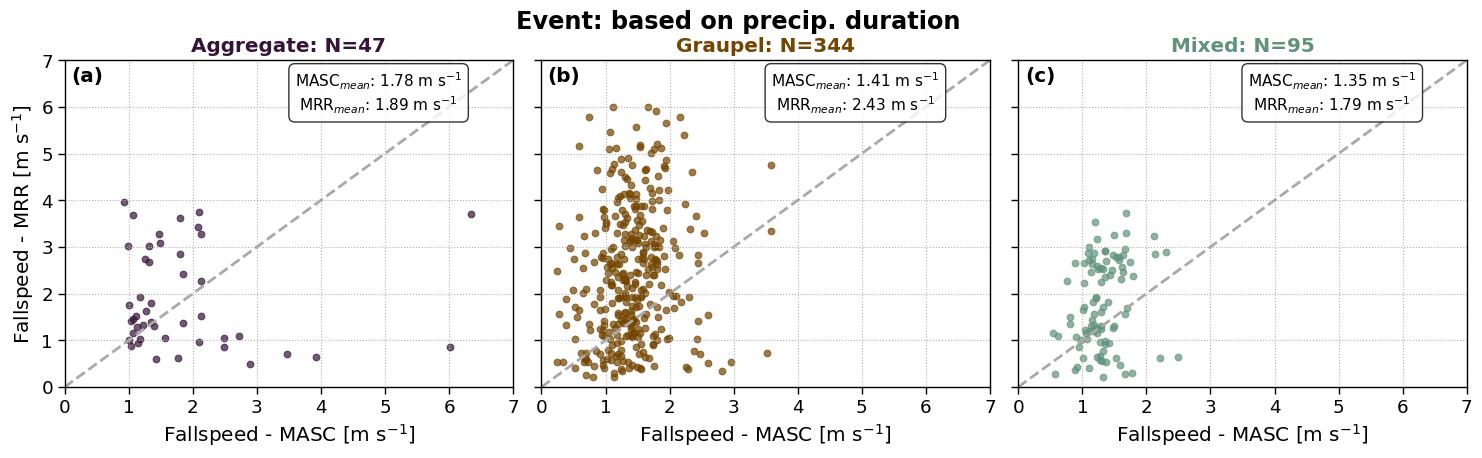

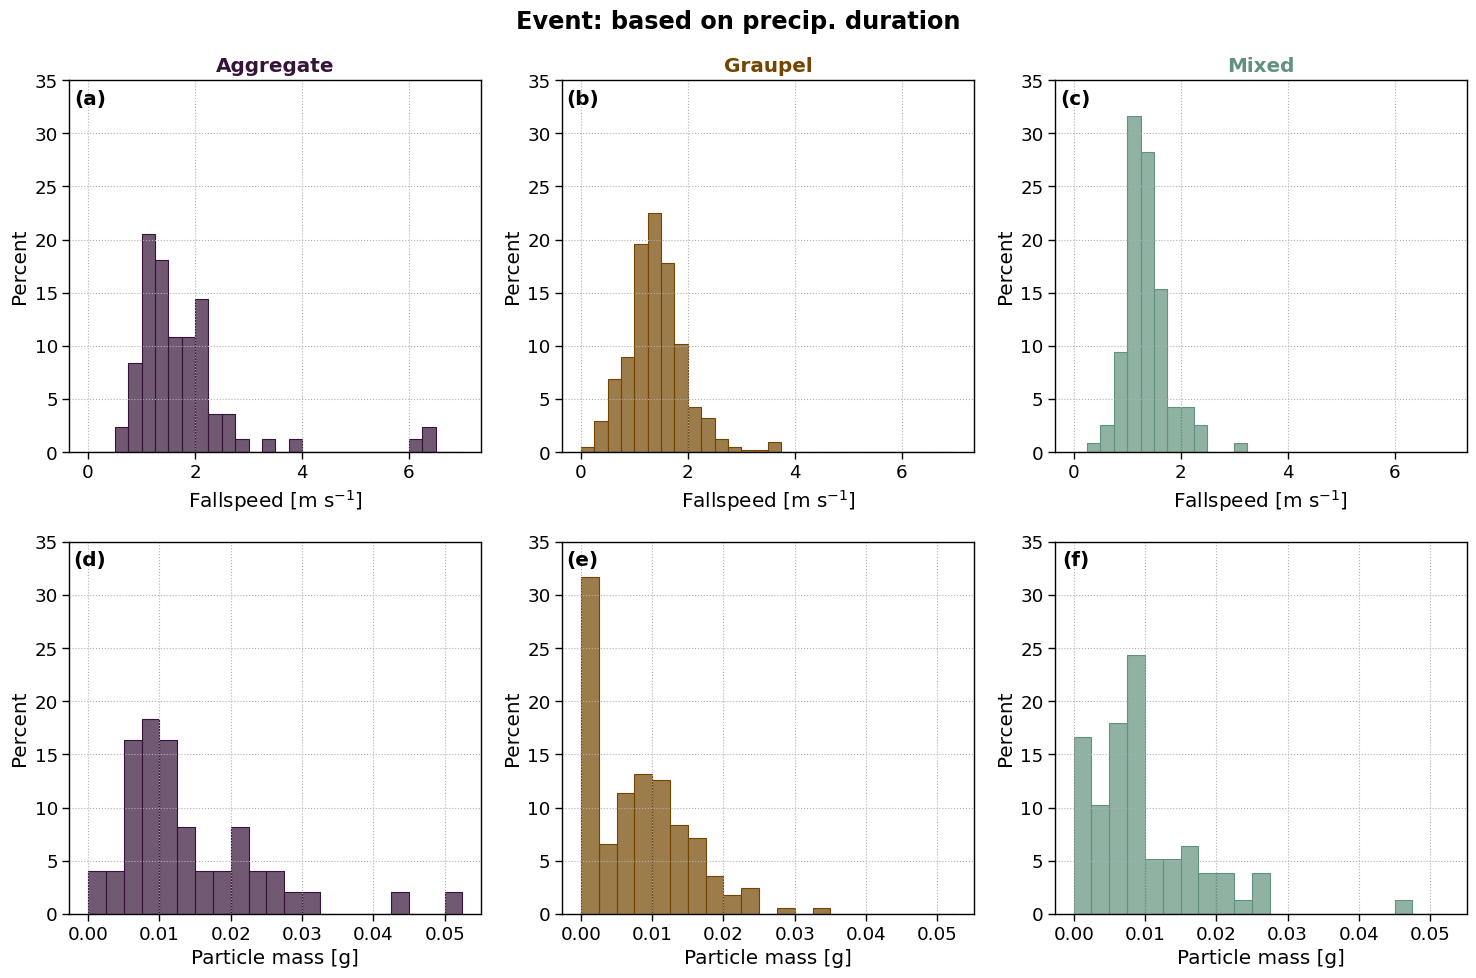

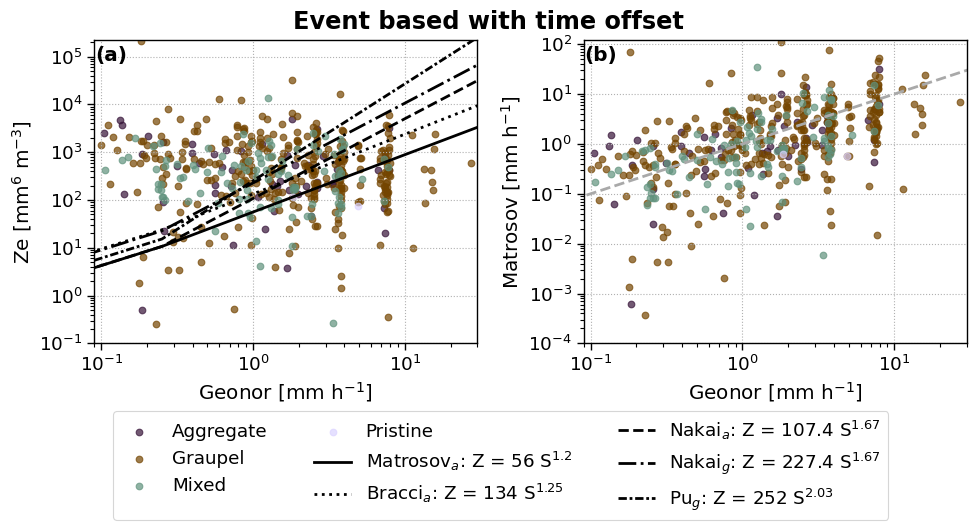

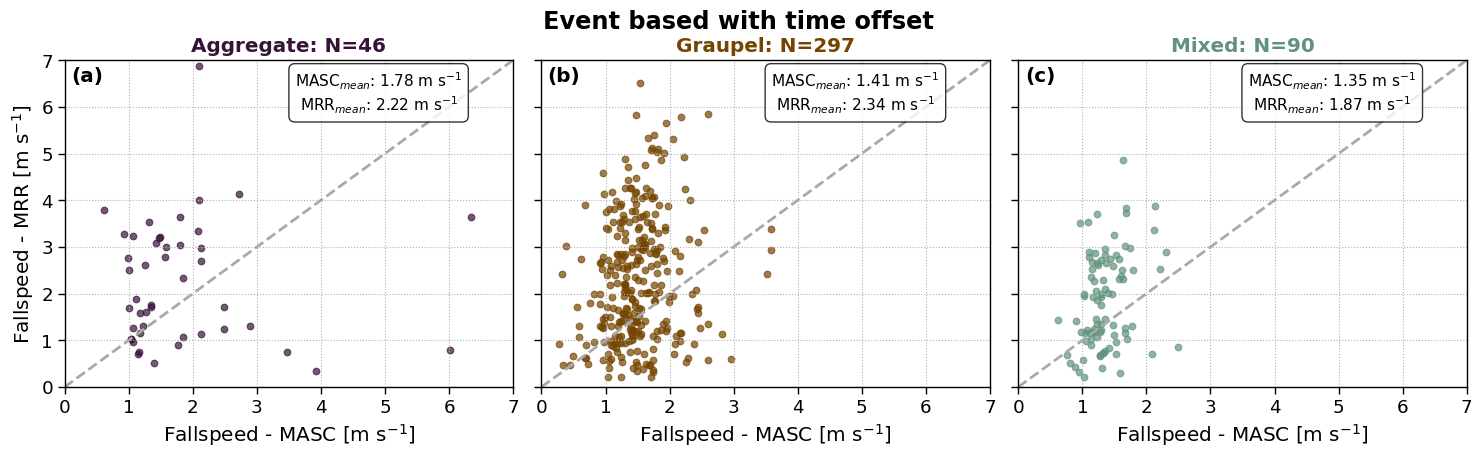

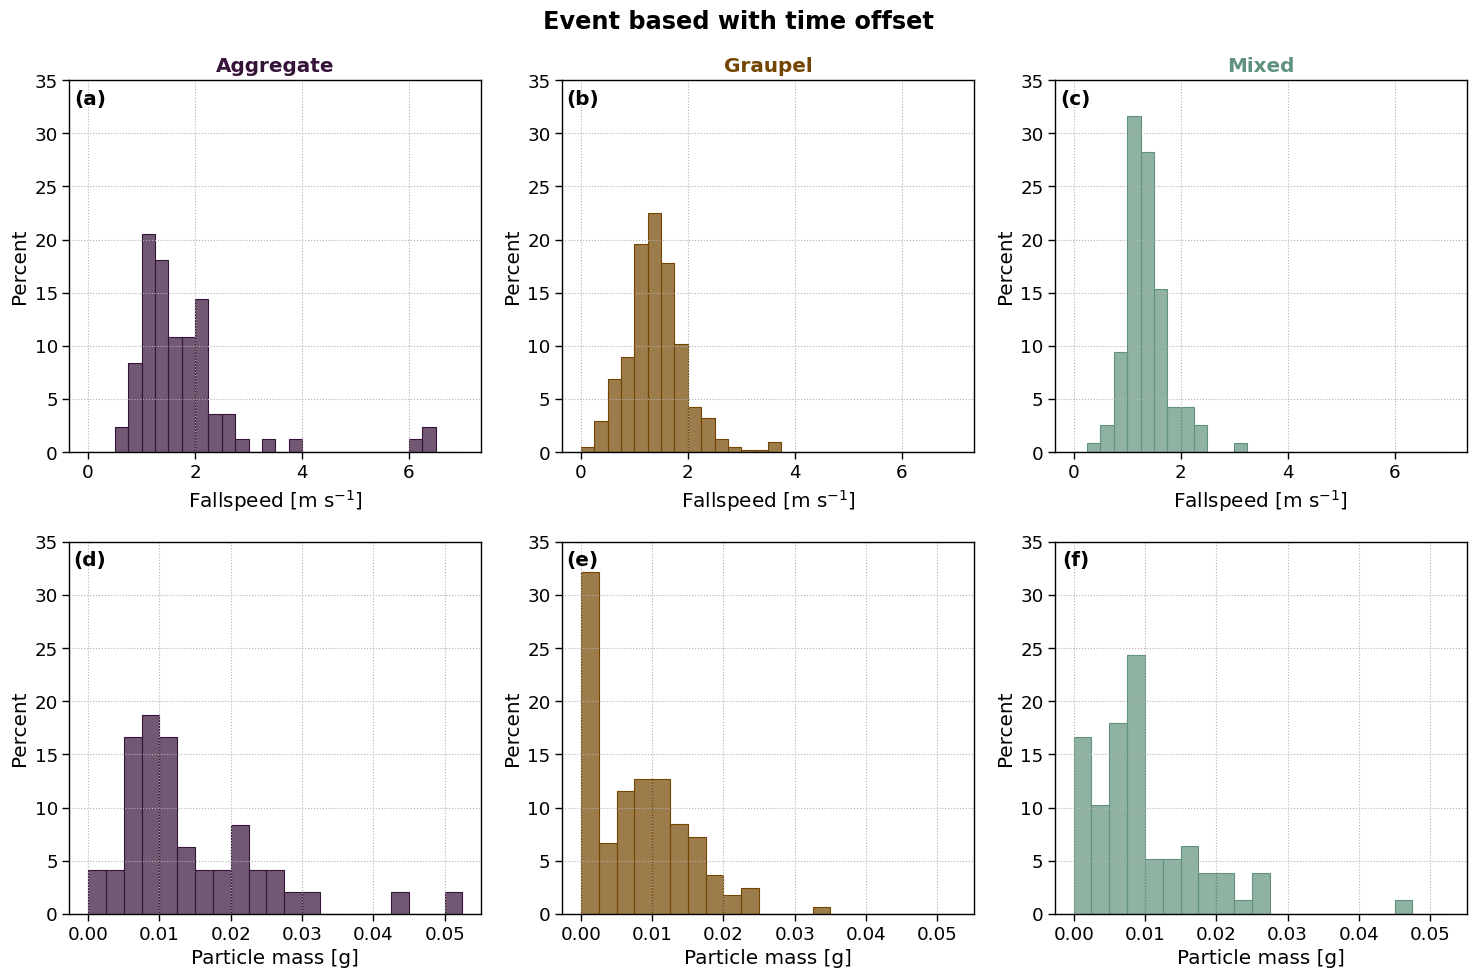

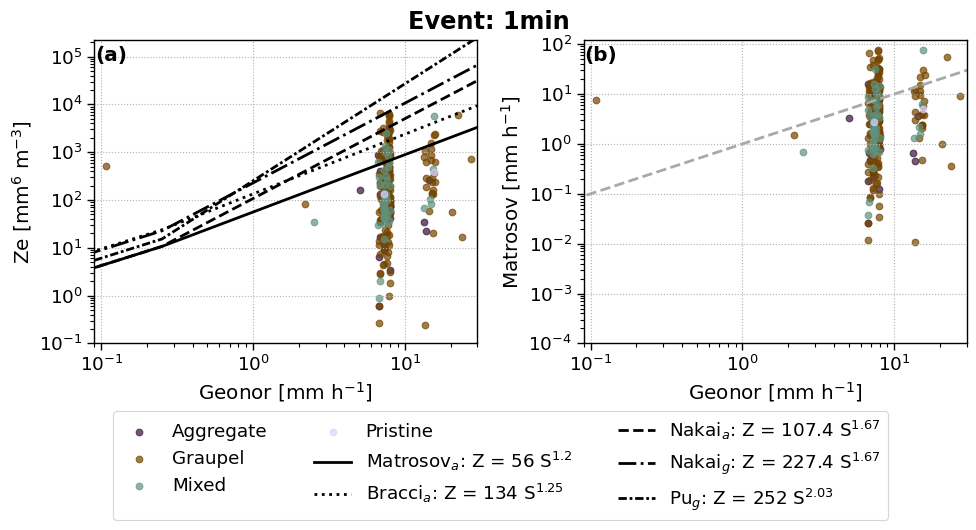

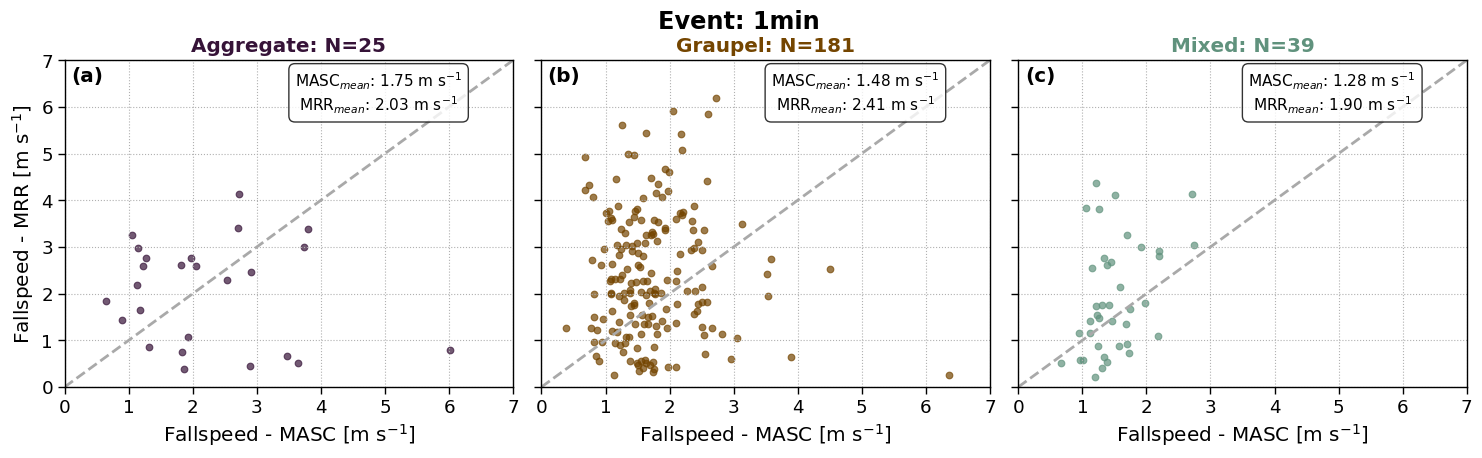

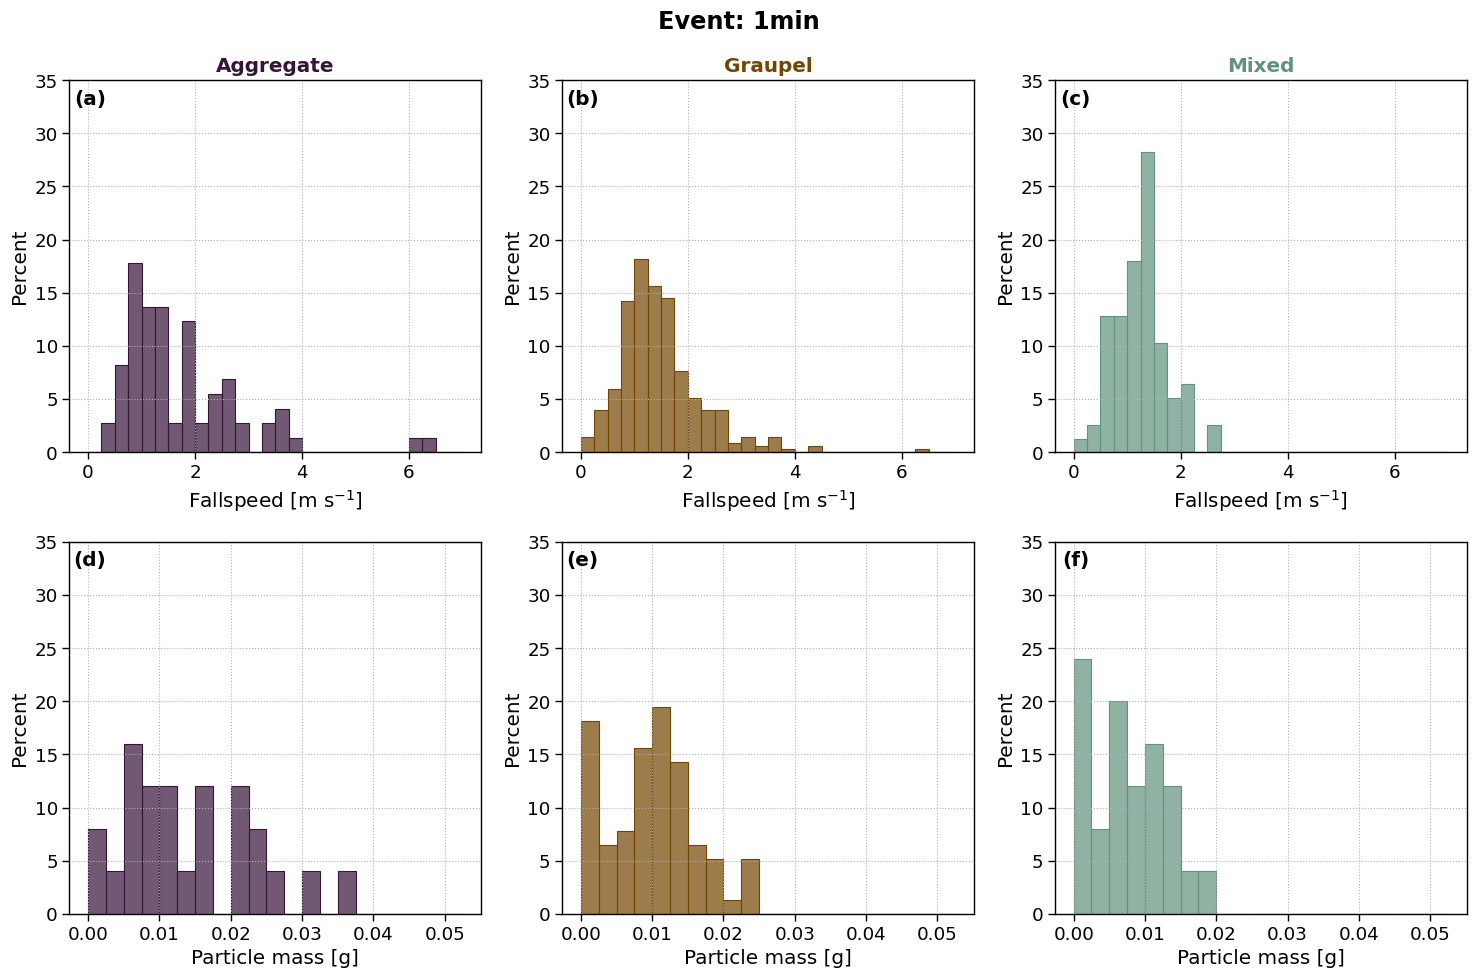

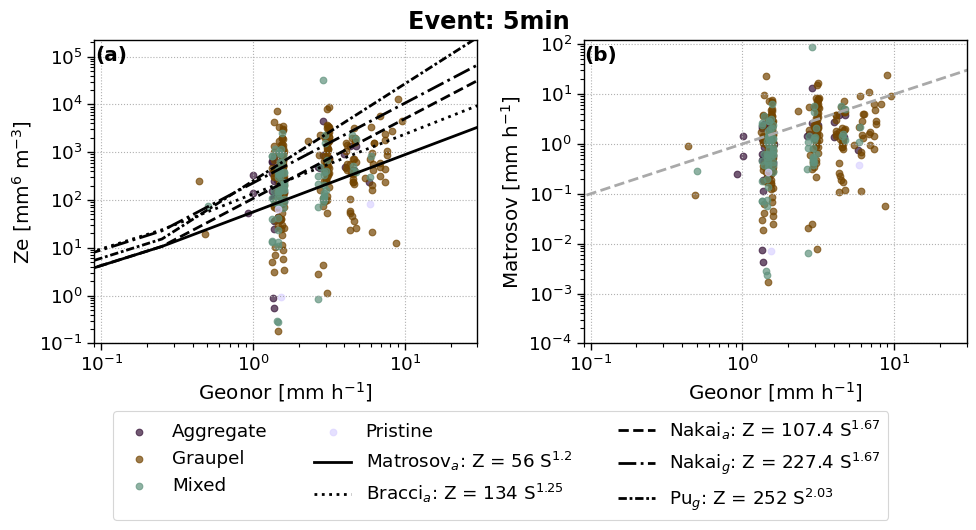

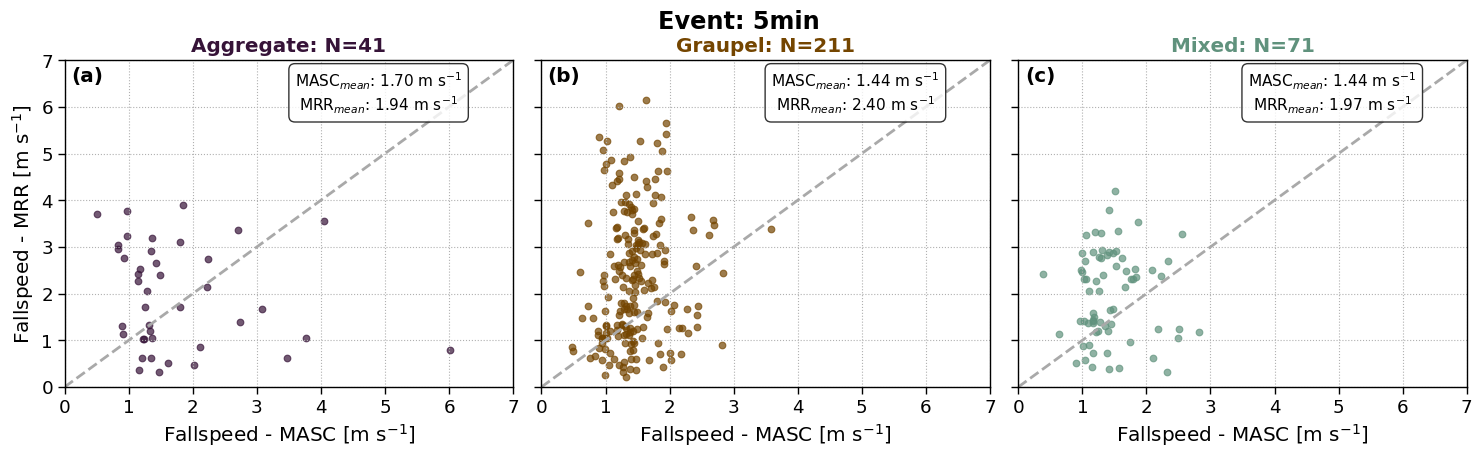

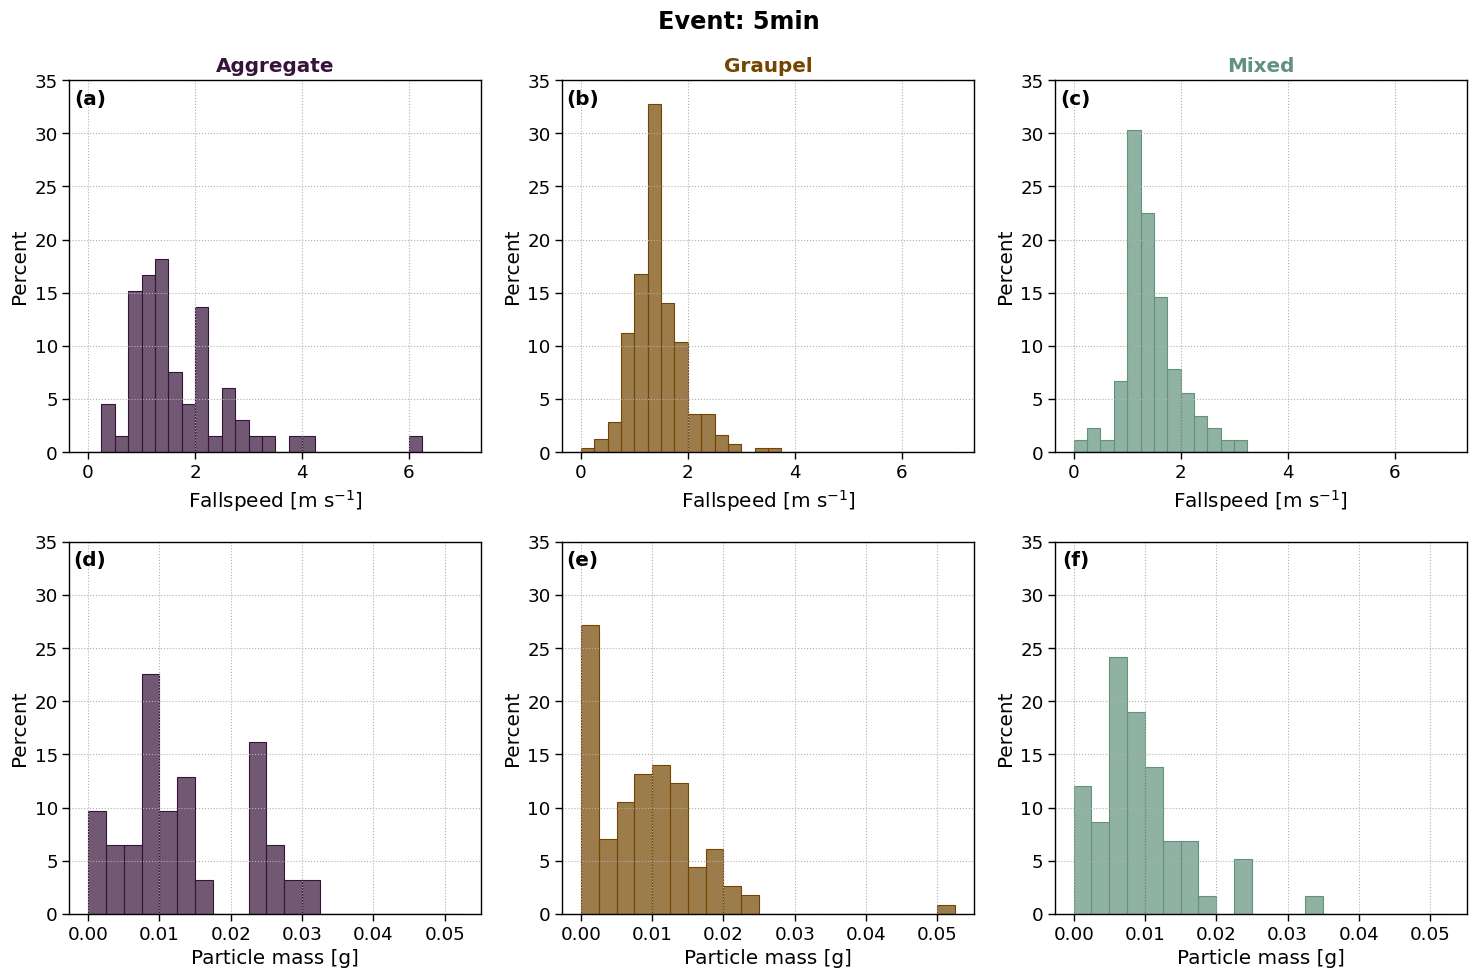

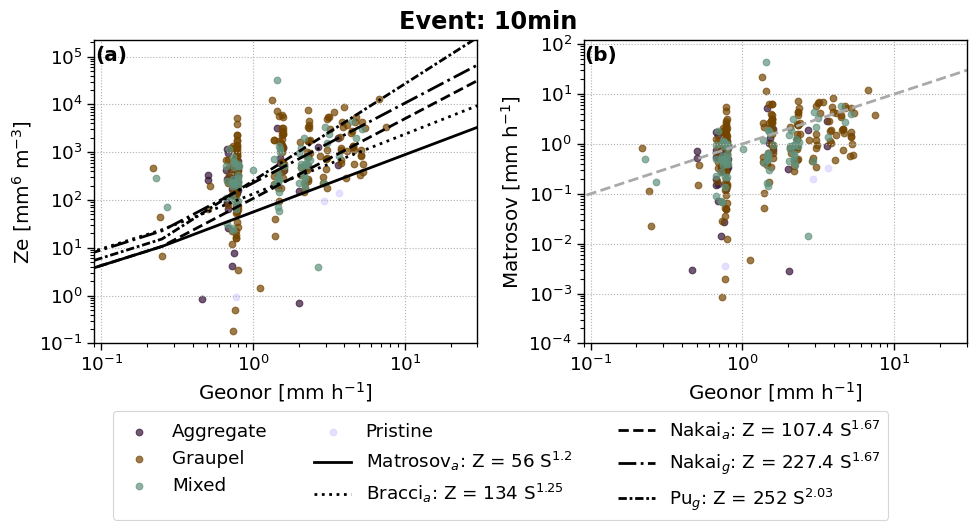

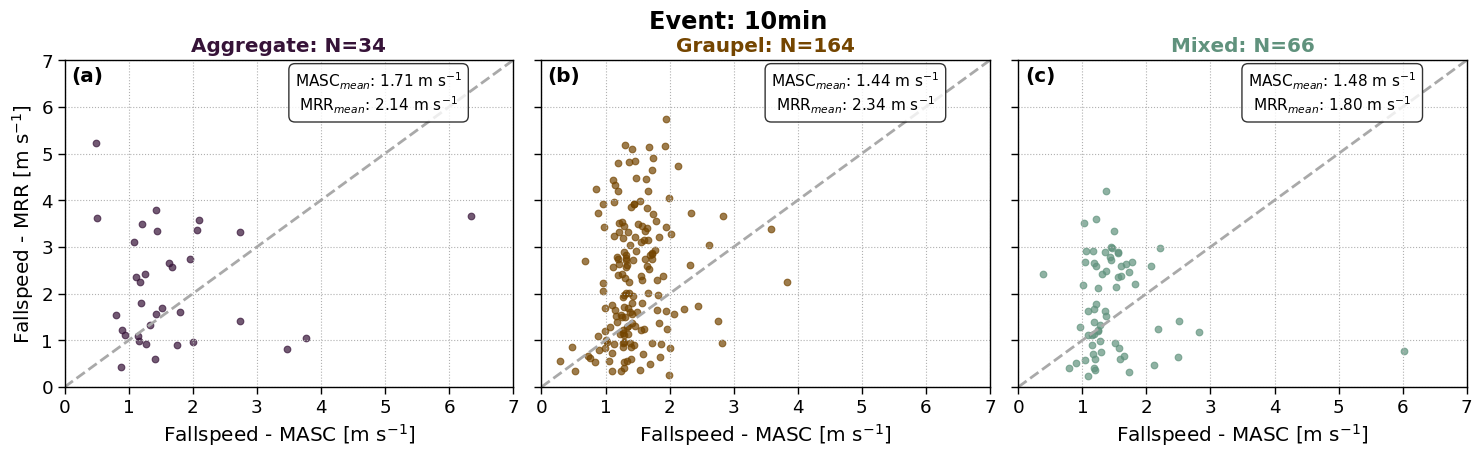

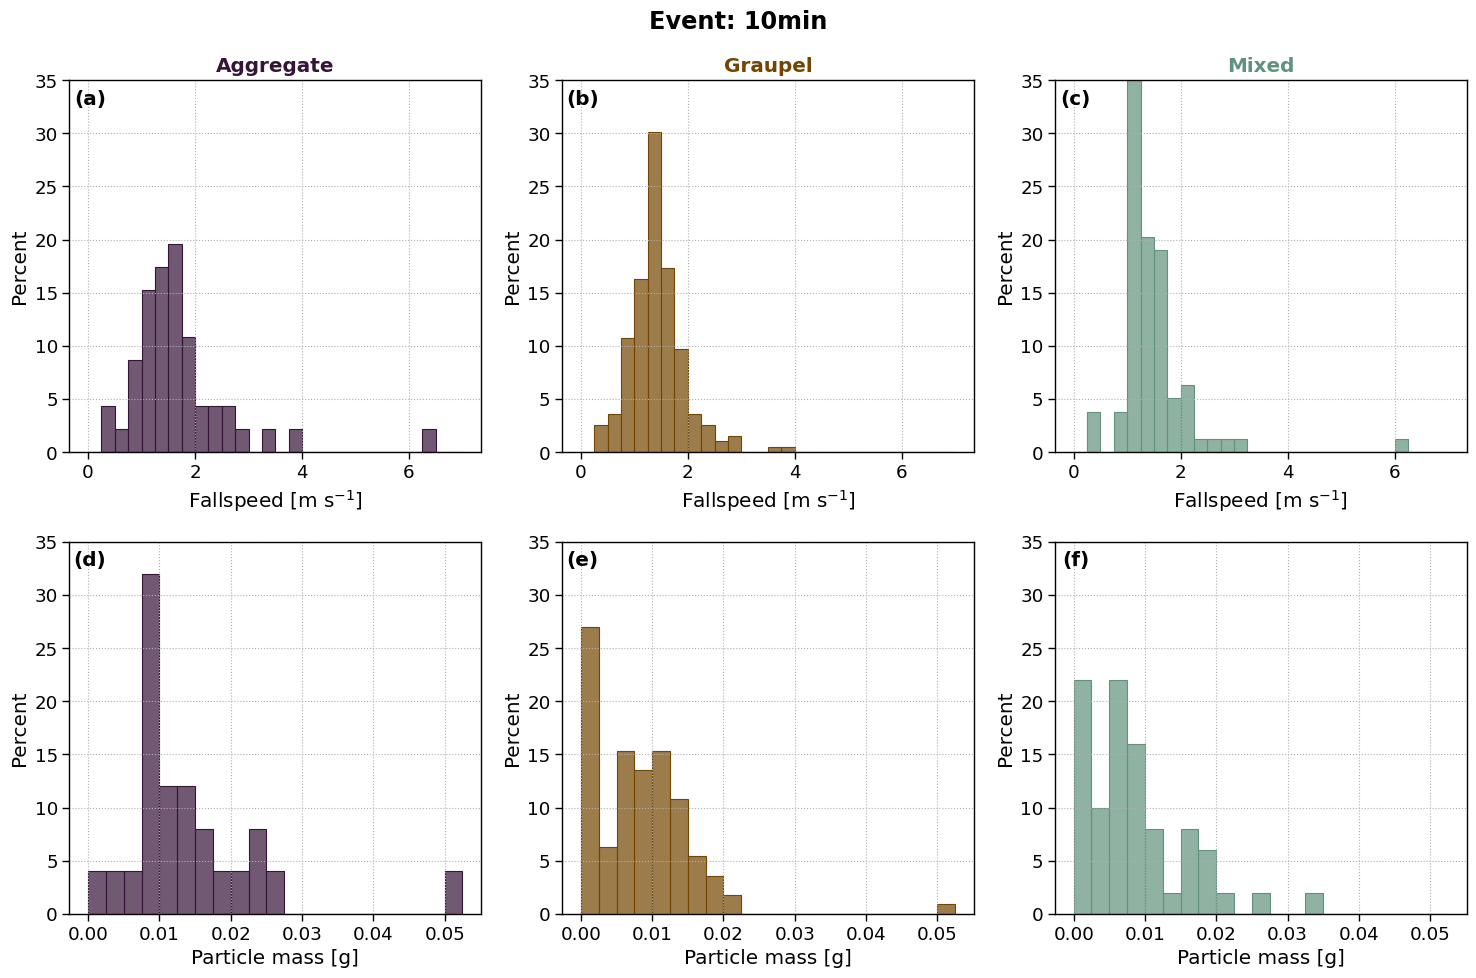

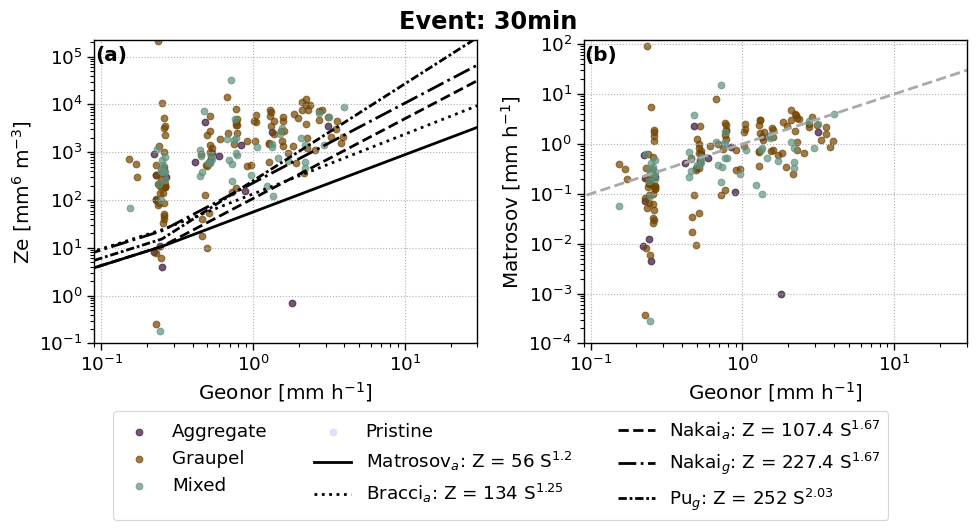

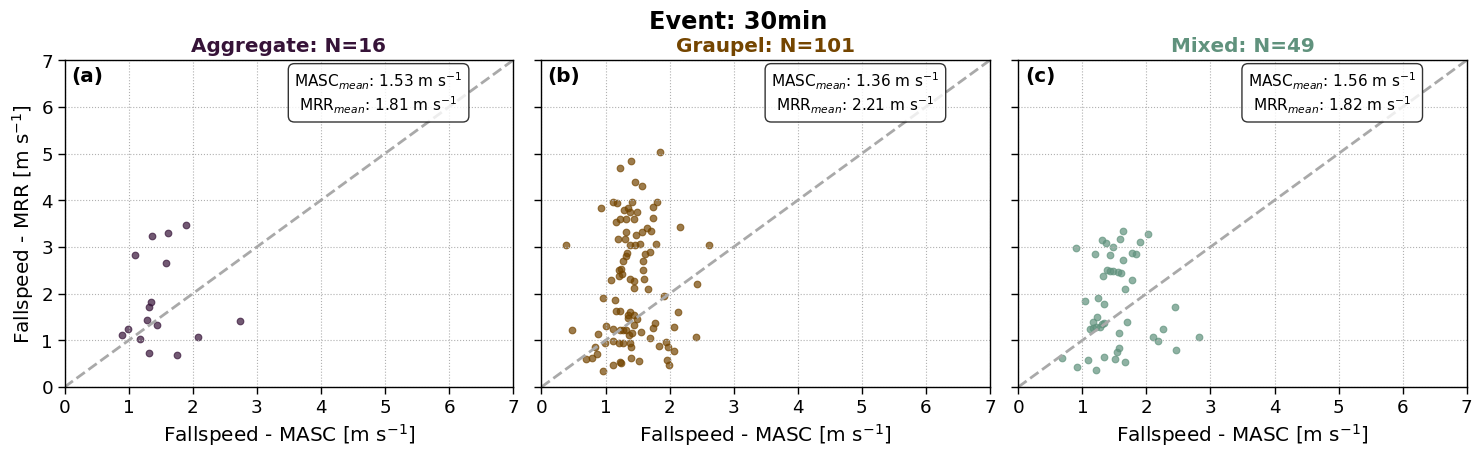

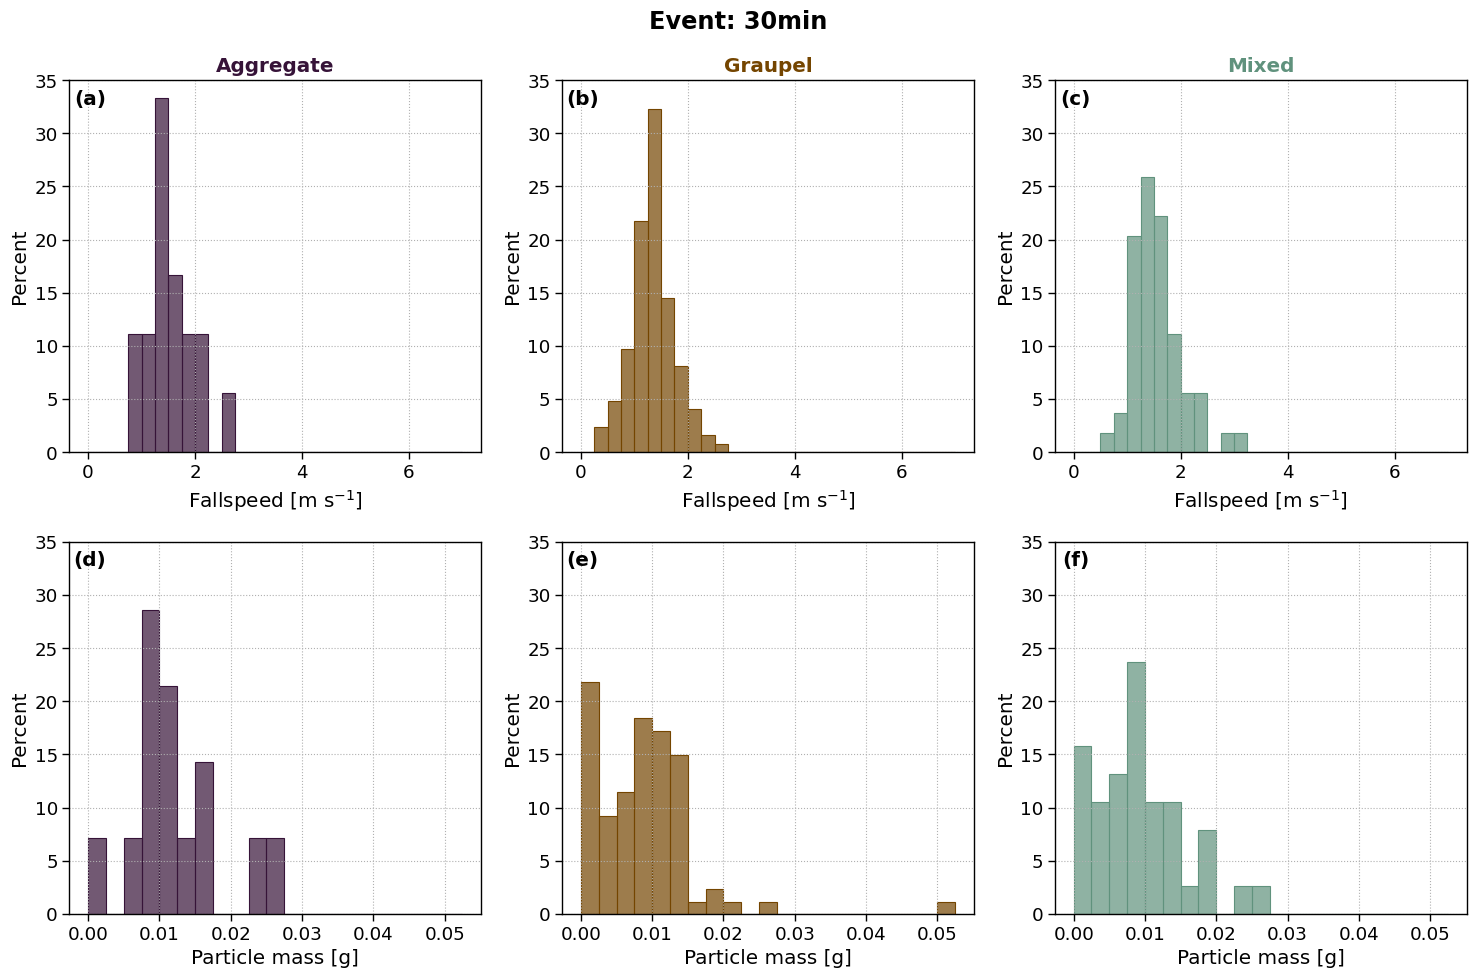

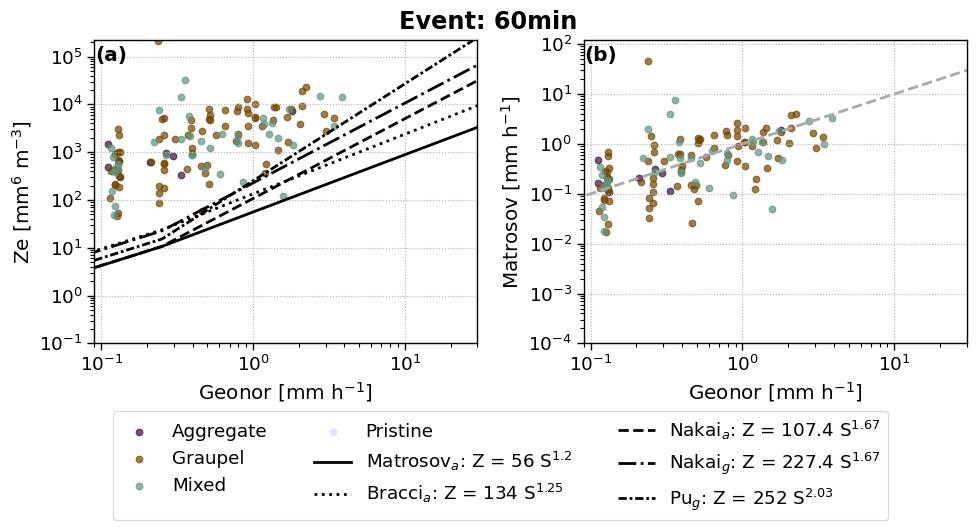

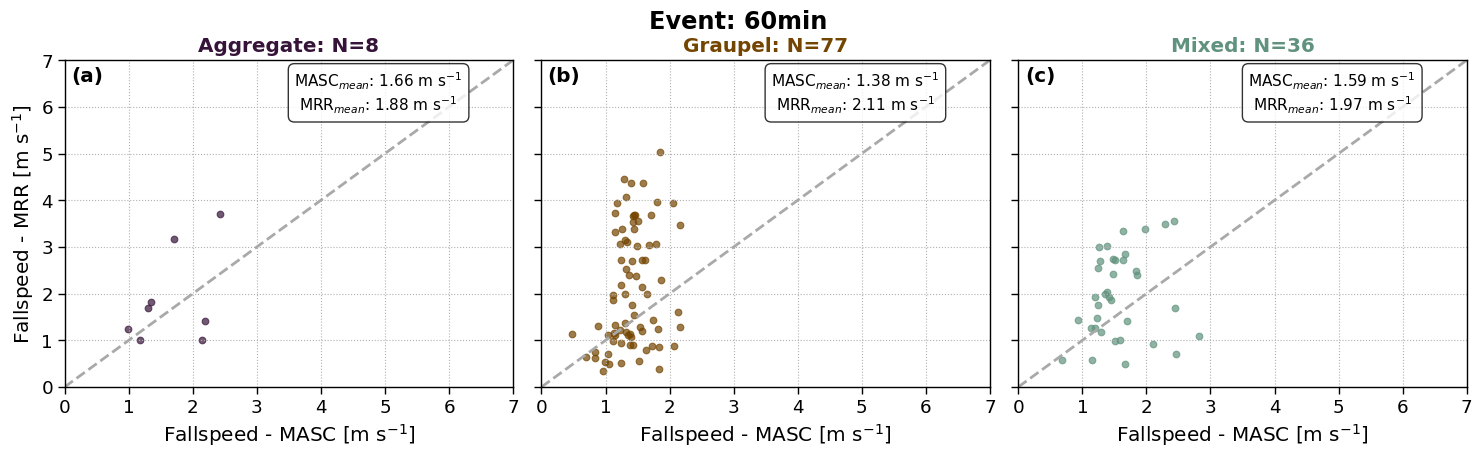

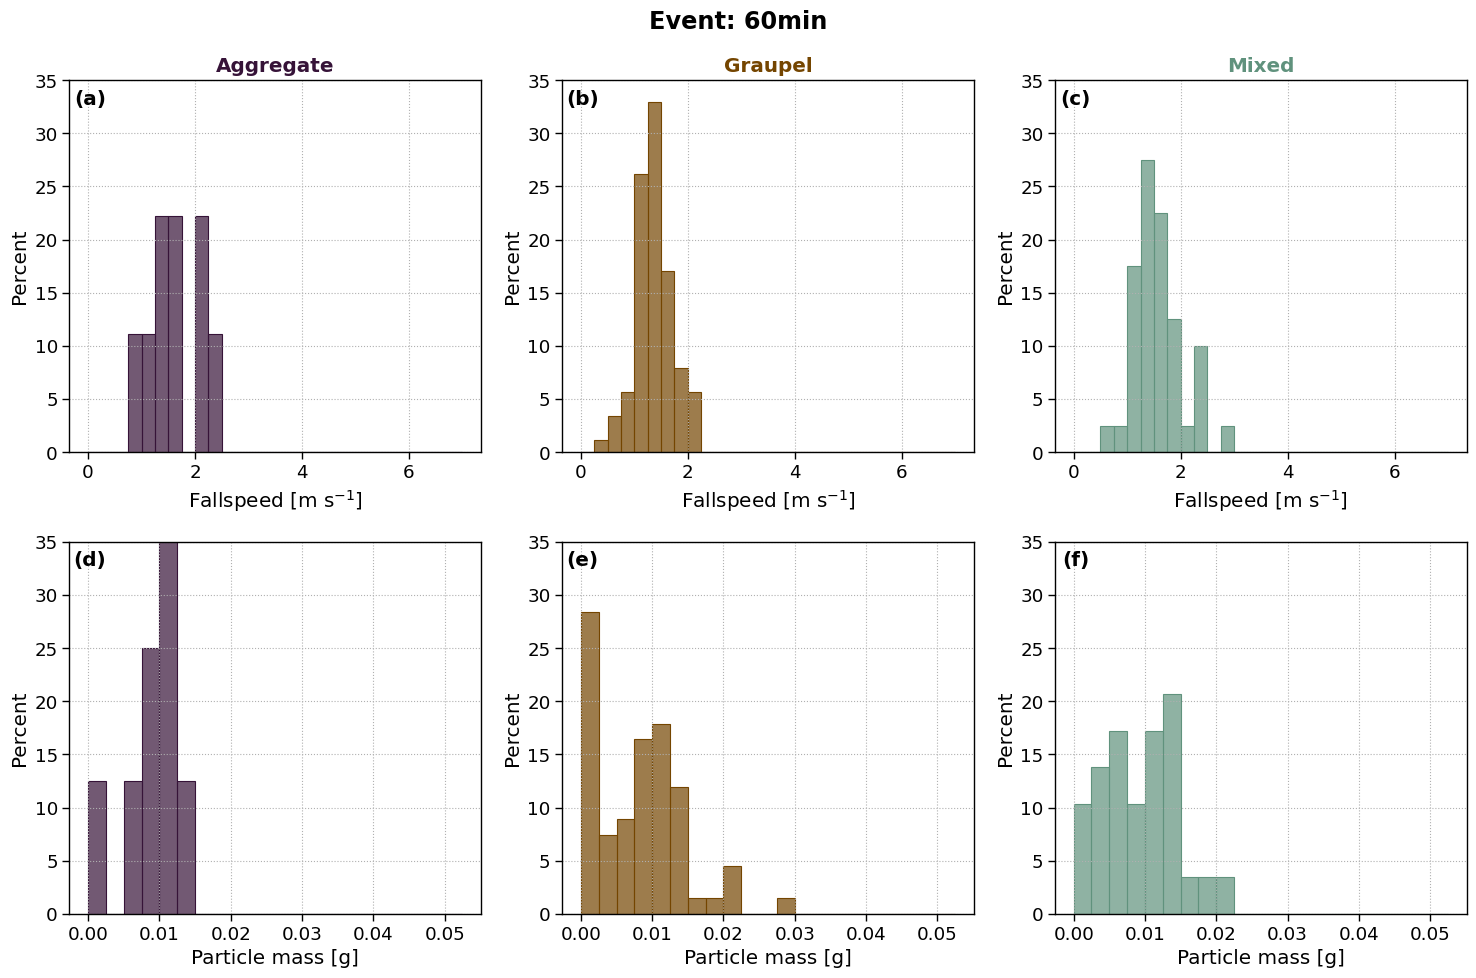

In [11]:
for duration, title in zip(df.keys(), ["Event: based on precip. duration", "Event based with time offset", "Event: 1min", "Event: 5min", "Event: 10min", "Event: 30min", "Event: 60min"]):
    fct.plt_geonor_vs_ze_vs_precip_scatter(ylabels= ['Ze [mm${^6}$ m$^{-3}]$', 'Matrosov [mm h$^{-1}$]'], class_based=True, df_only_class=df_only_class[duration], xlim=[0.09, 30],  ylim_panel0=[0.1, 220000], ylim_panel1=[0.0001, 120], title=title)

    fct.plt_masc_vs_mrr_fallspeed(class_based=True, df_only_class=df_only_class[duration], panel_keys=['aggregate', 'graupel', 'mixed'], altitude_for_classes=400, xlim=(0.0, 7.0), ylim=(0.0, 7.0), title=title)

    fct.plt_fallspeed_distribution_by_class(df_only_class[duration], binrange_v=[0,7], binrange_m=[0, 0.0525], binwidth=0.25, stat='percent', title = title)

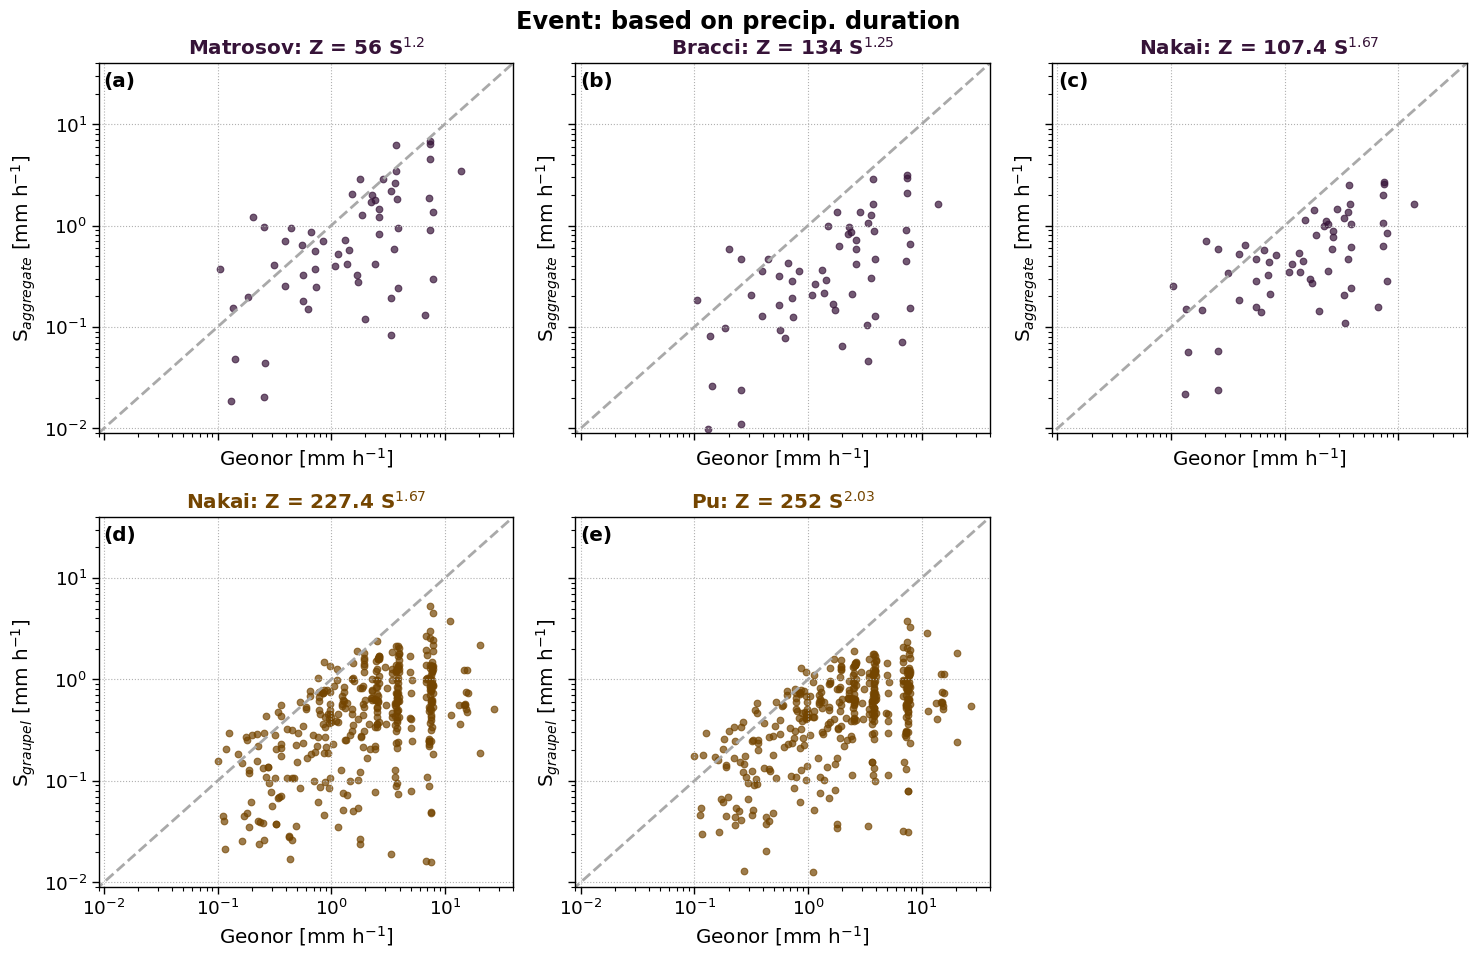

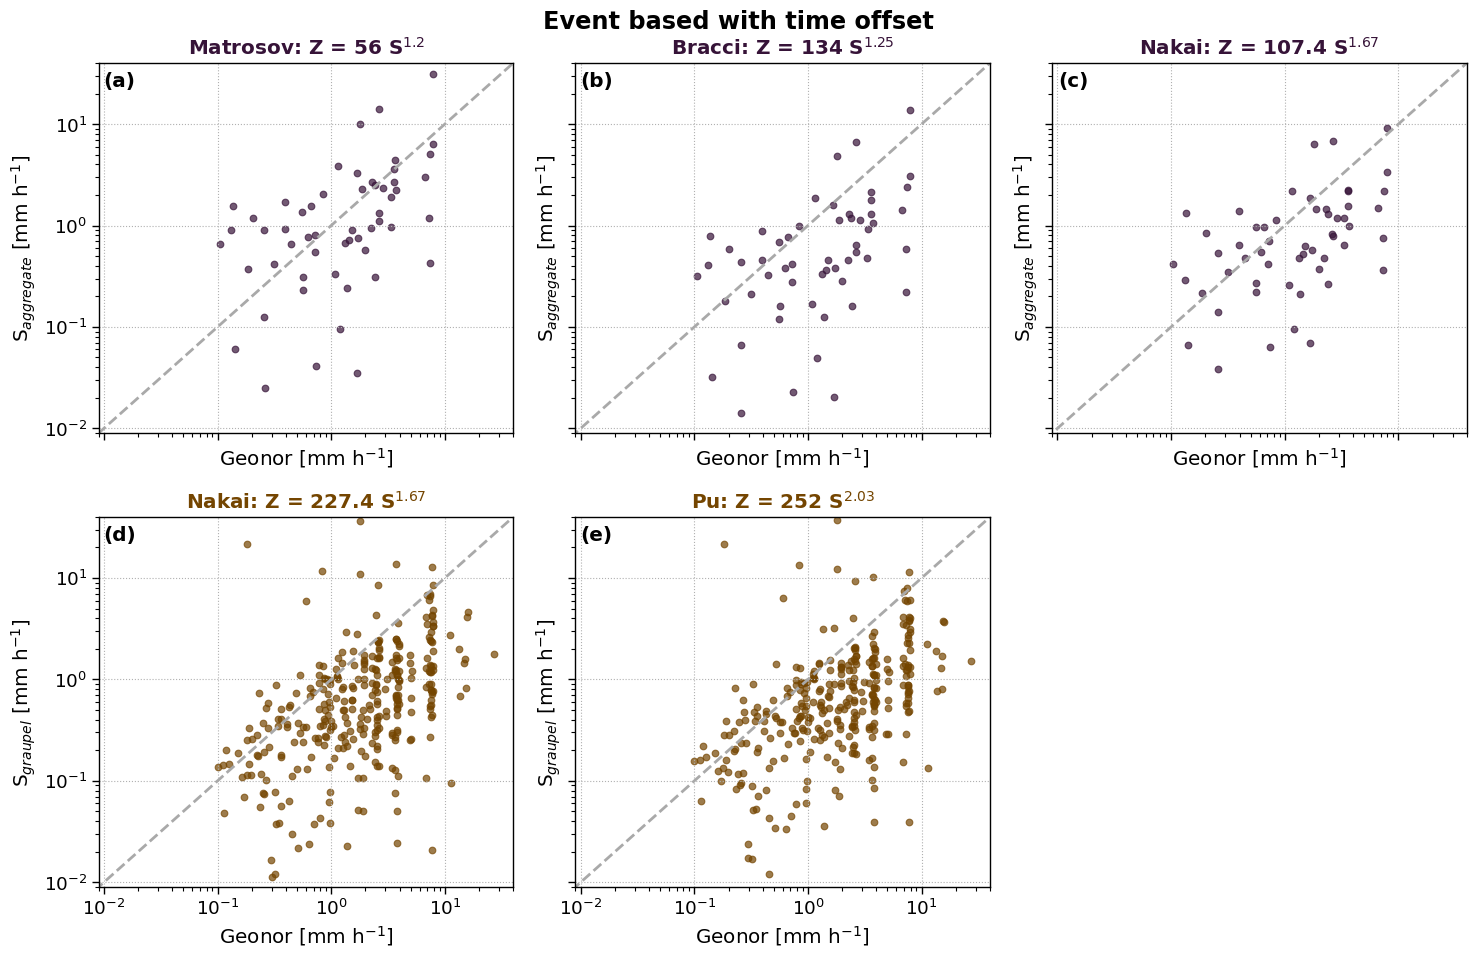

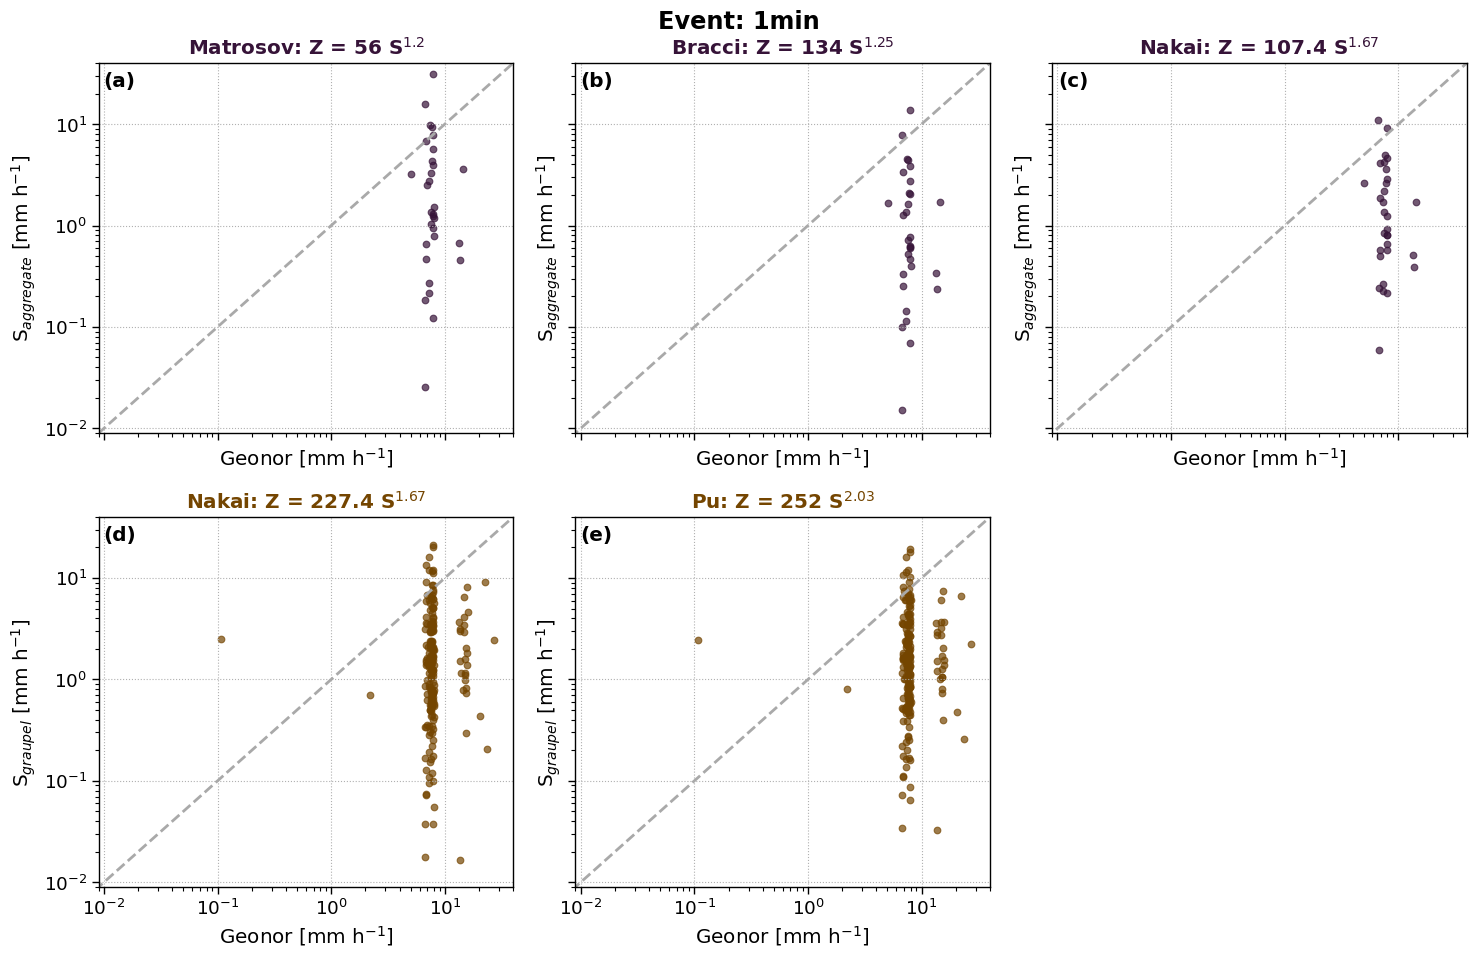

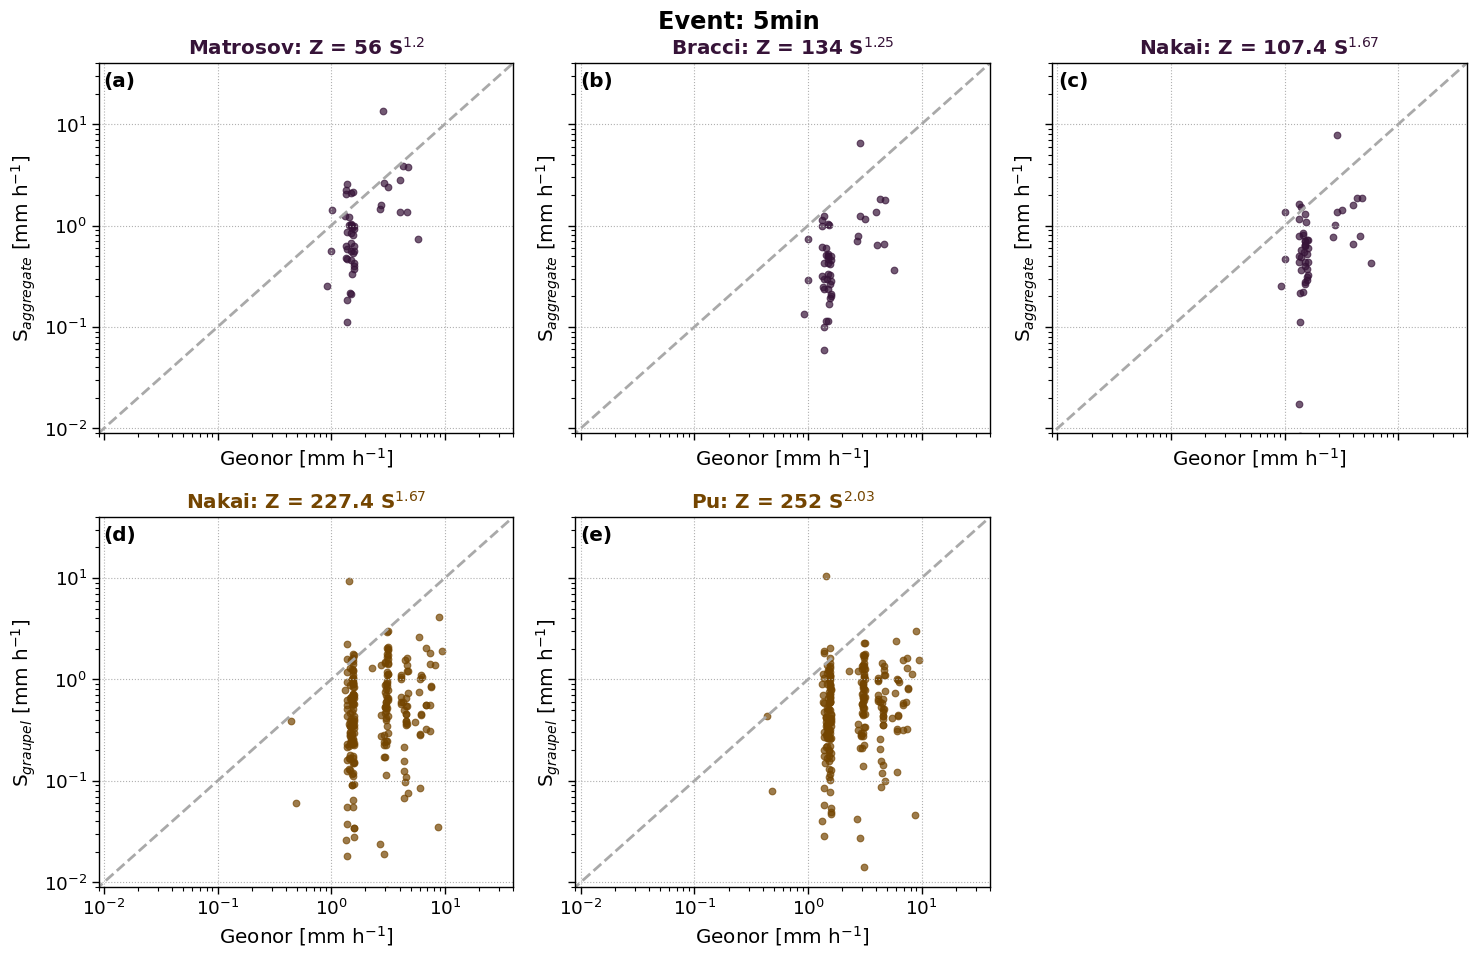

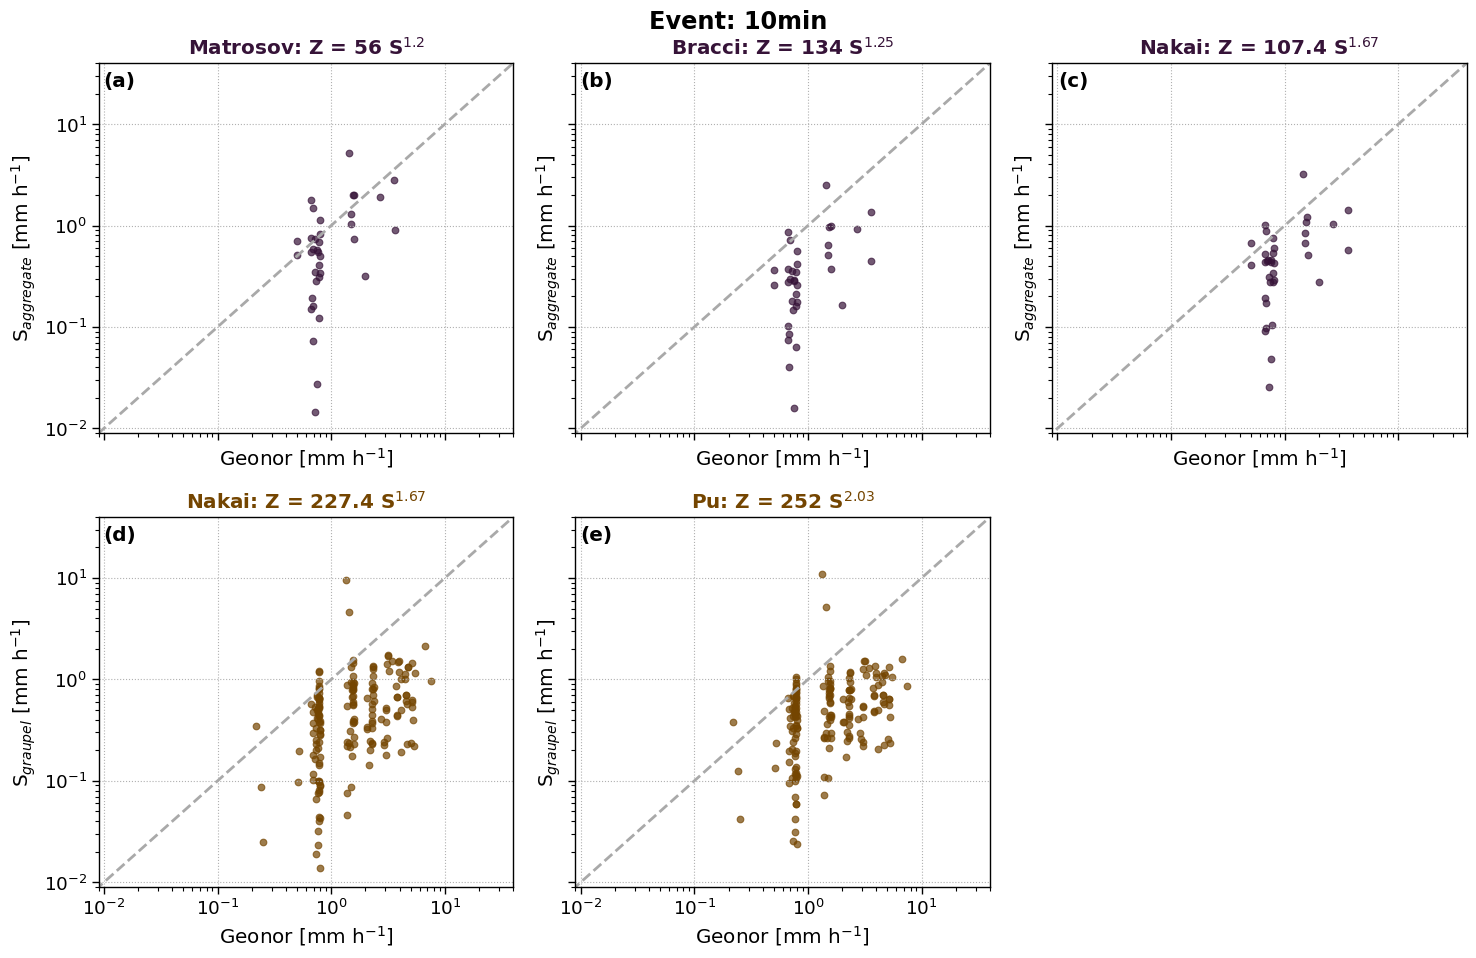

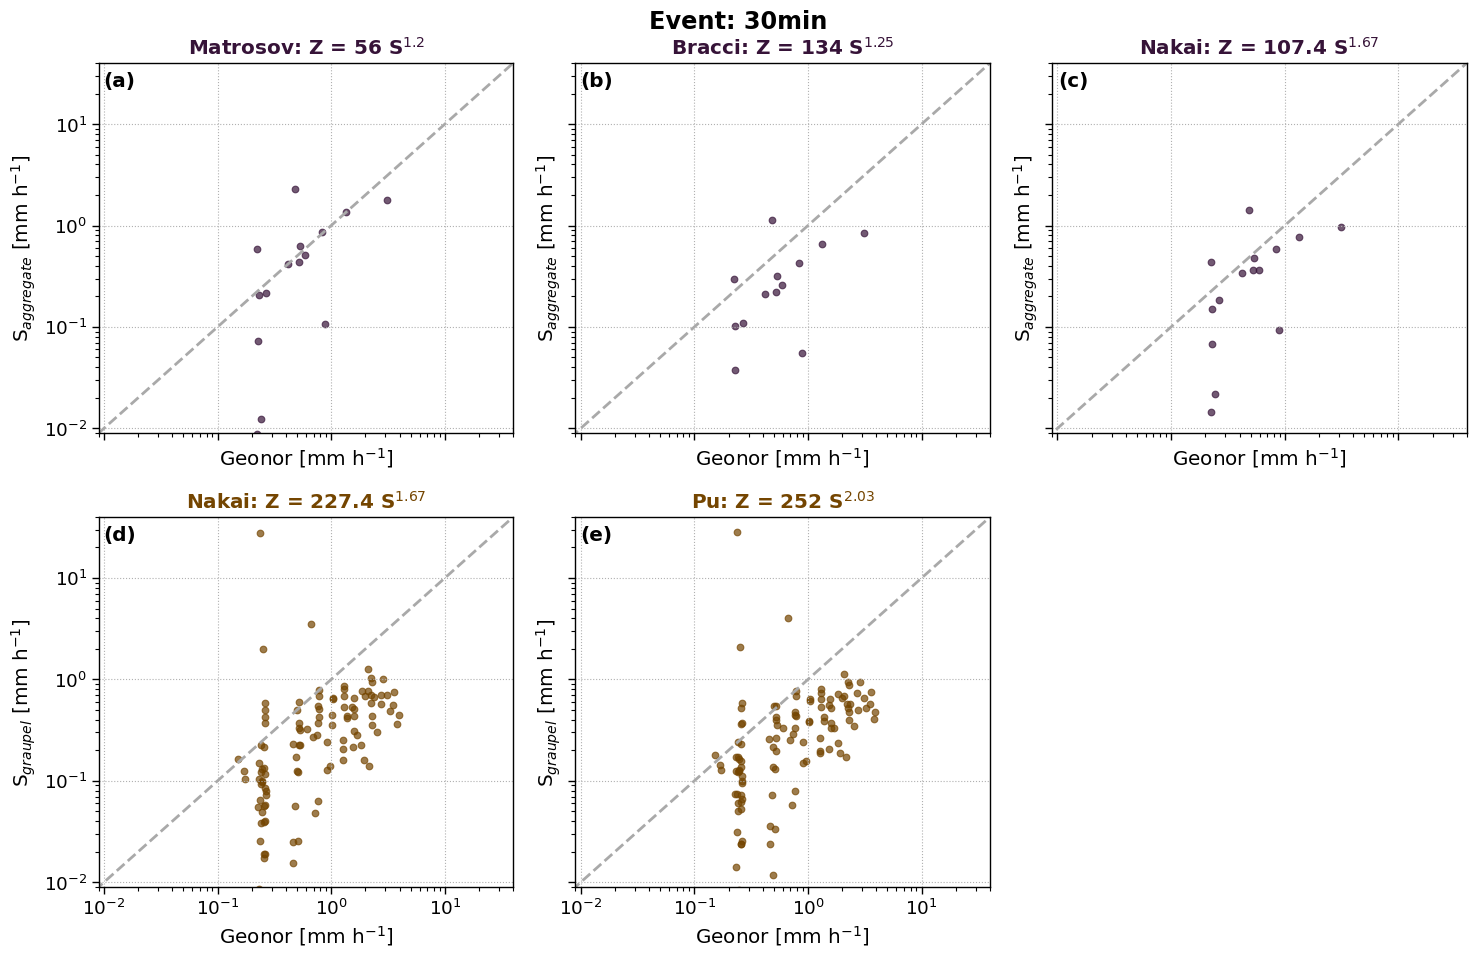

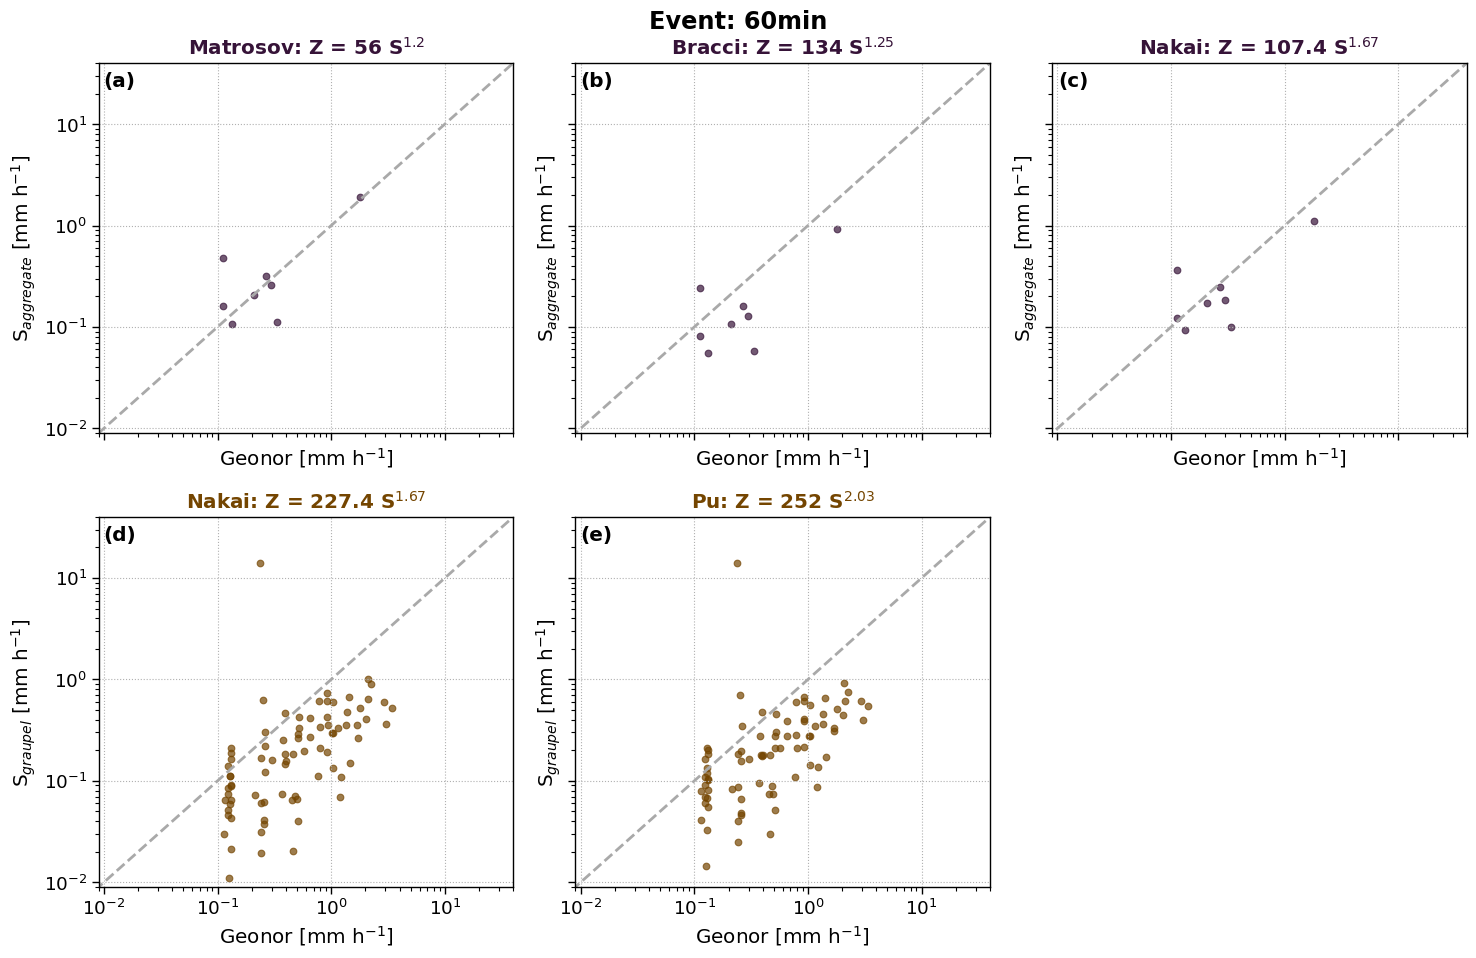

In [12]:
for duration, title in zip(df.keys(), ["Event: based on precip. duration", "Event based with time offset", "Event: 1min", "Event: 5min", "Event: 10min", "Event: 30min", "Event: 60min"]):
    fct.plt_precip_scatter_literature(df_only_class[duration], title=title)

In [13]:
xval = df['event']['Matrosov_from_ze_sum_400']*(60*df['event']['delta_h'])
yval = df['event']['Ze_linear_sum_400']

In [14]:
xval = df['event']['rate_mm_h'] * (60*df['event']['delta_h'])
yval = df['event']['Ze_linear_sum_400']

In [15]:
valid = (~np.isnan(xval)) & (~np.isnan(yval))
xclean = xval[valid]
yclean = yval[valid]

# Log-linear regressions ln(y) = ln(a) + b*ln(x) --> gives a straight line
logx = np.log(xclean)
logy = np.log(yclean)


# Linear regression on log-log data
b2, loga = np.polyfit(logx, logy, 1)
a2 = np.exp(loga)

print(f"Fit: Z = {a2:.3f} * S^{b2:.3f}")

# Nonlinear curve fitting 
# the curve fitting is done with an iterative nonlinear optimization. The optimizer starts at the guess p0, then tries to minimize the squared error between the model and the data. A good initial guess helps the optimizer converge quickly and to get the right solution. 
# From the log-linear regression we get a quick estimate of a and b, that's why we use those as p0
params, cov = curve_fit(fct.model, xclean, yclean, p0=(a2, b2))
a, b = params
print(f"Fit: Z = {a:.3f} * S^{b:.3f}")


Fit: Z = 38.162 * S^0.858
Fit: Z = 140.598 * S^0.731


### Find b-values: $b_m$, $b_{\nu}$ 
$$b_{zs} = \frac{b_{\sigma} +1}{b_m + b_{\nu} +1}$$

- use data per 30' particle measurement (mean)
    - maximum dimension: D = ```flake_Dmax```
    - particle mass: m = ```gan3d_mass```
    - fallspeed: $\nu$ = ```fallspeed```

-  Preprocessing:
    - filter invalid values ($D>0$, $m>0$, $\nu>0$)
    - transform to log-log space
        - $log_{10}m$, $log_{10}\nu$ vs. $log_{10}D$
- Fitting:
    - linear (deg=1)
    - $log_{10}m = log_{10} a_m + b_m log_{10}D$
    - $log_{10}\nu = log_{10} a_{\nu} + b_{\nu} log_{10}D$

### Backscatter / Reflectivity fits
- use data per 30' particle measurement 
    - particle size distribution: N(D)
    - Radar reflectivity ($\sum$): $Z_{obs}$ [$mm^{6} m^{-3}$]
    - not directly available: backscatter cross-section: $\sigma(D)$
        - $\rightarrow$ measure: radar reflectivity factor Z, which is integral over PSD
        - $Z = \int N(D) \sigma(D) dD$
    - invert the problem and assume parametrization
        - $\sigma(D) = a_{\sigma} D^{b_{\sigma}}$
    - predict reflectivity
        - $Z_{pred}(t) = a_{\sigma} \sum_j (D^{b_{\sigma}}) N_j(t) \Delta D_j$ 
    - minimize residuals vs. observed reflectivity
        - $min \sum_t(Z_{pred}(t) - Z_{obs}(t))^2$


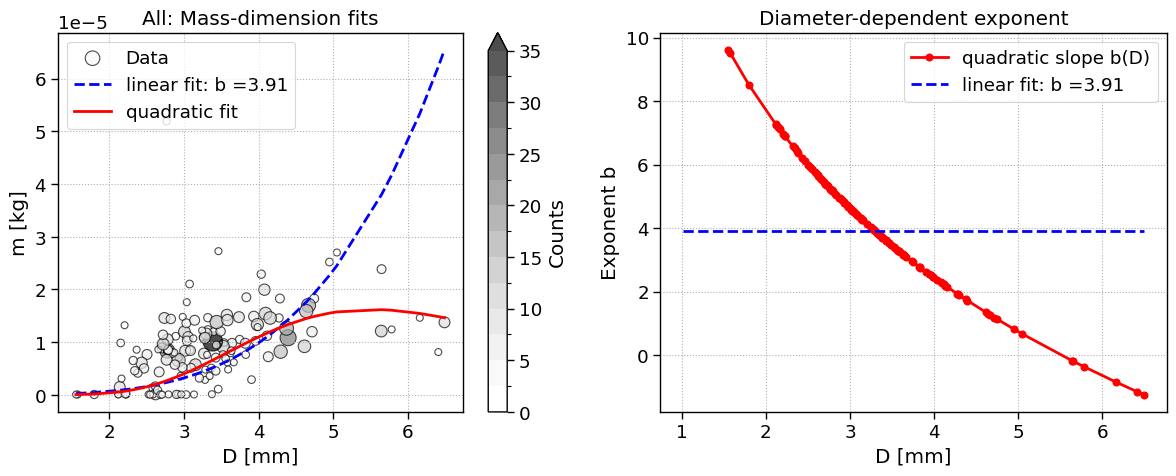

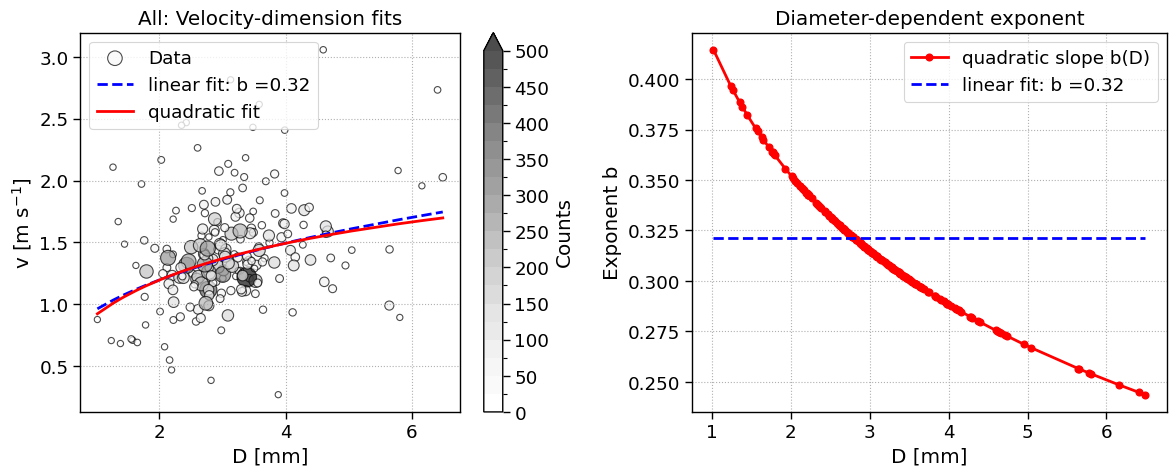

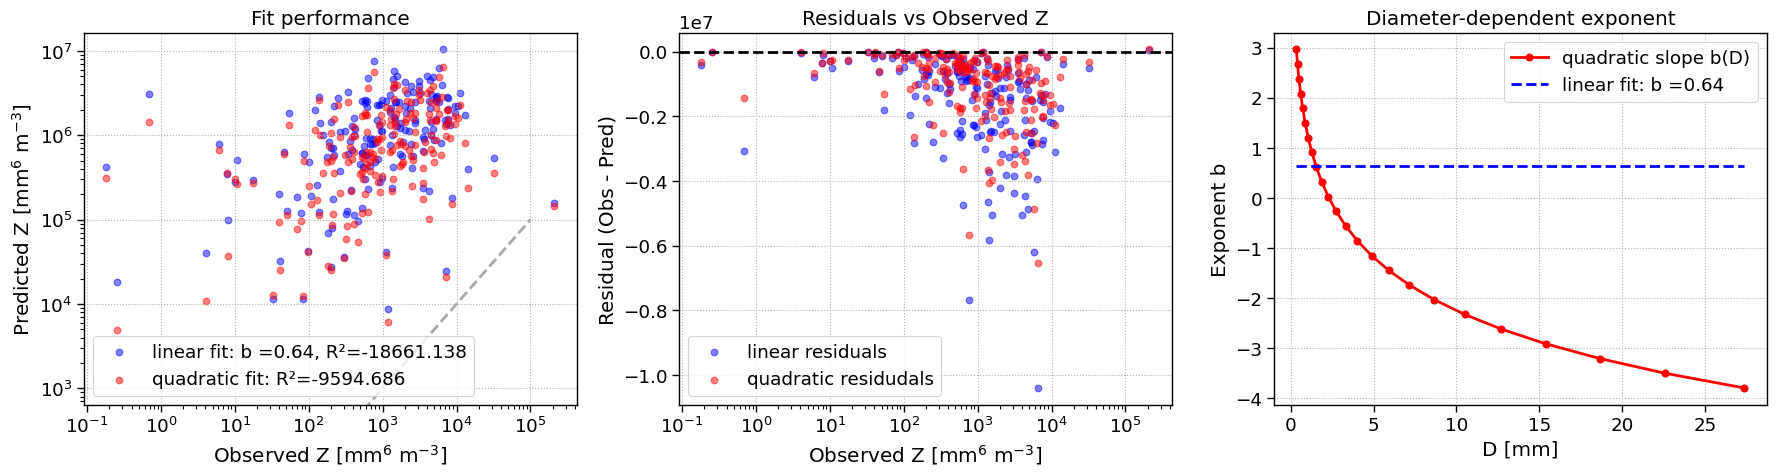

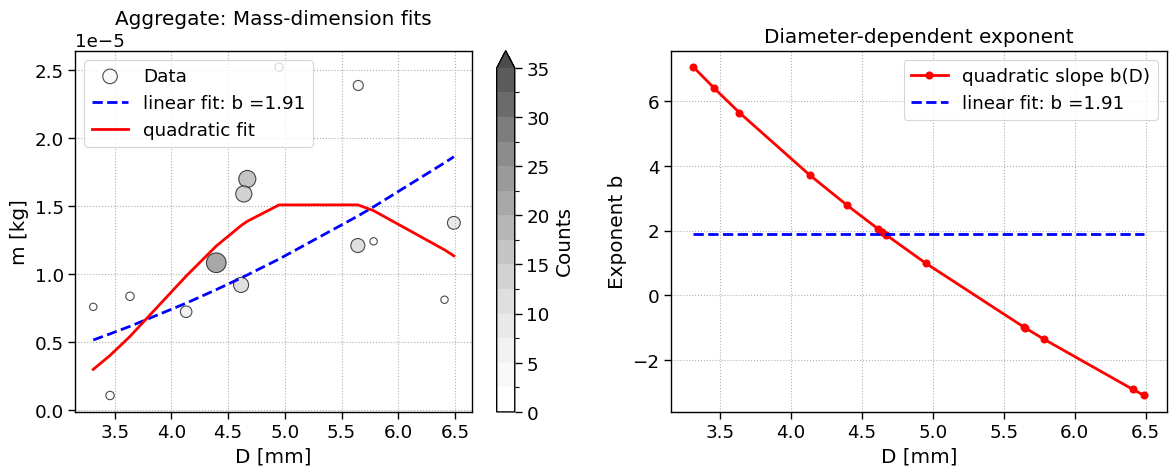

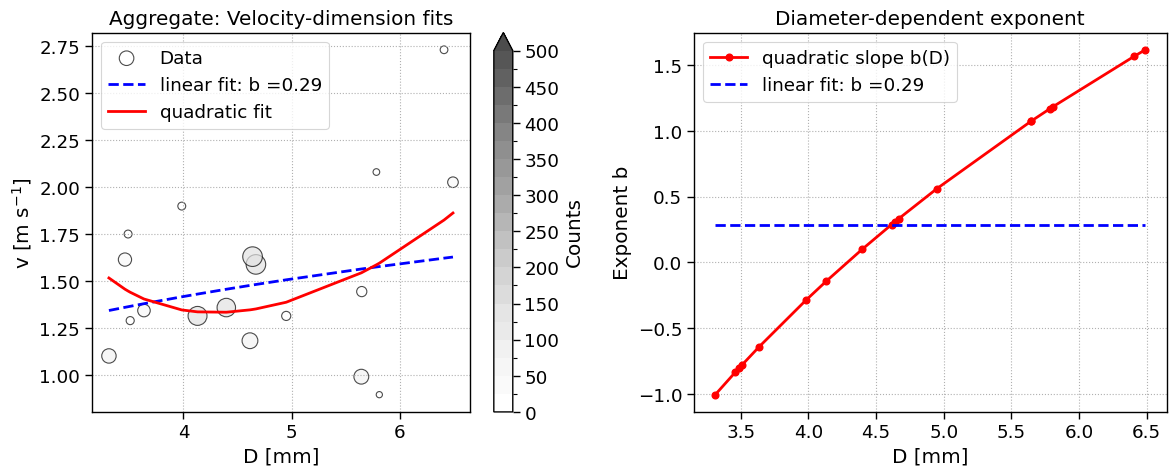

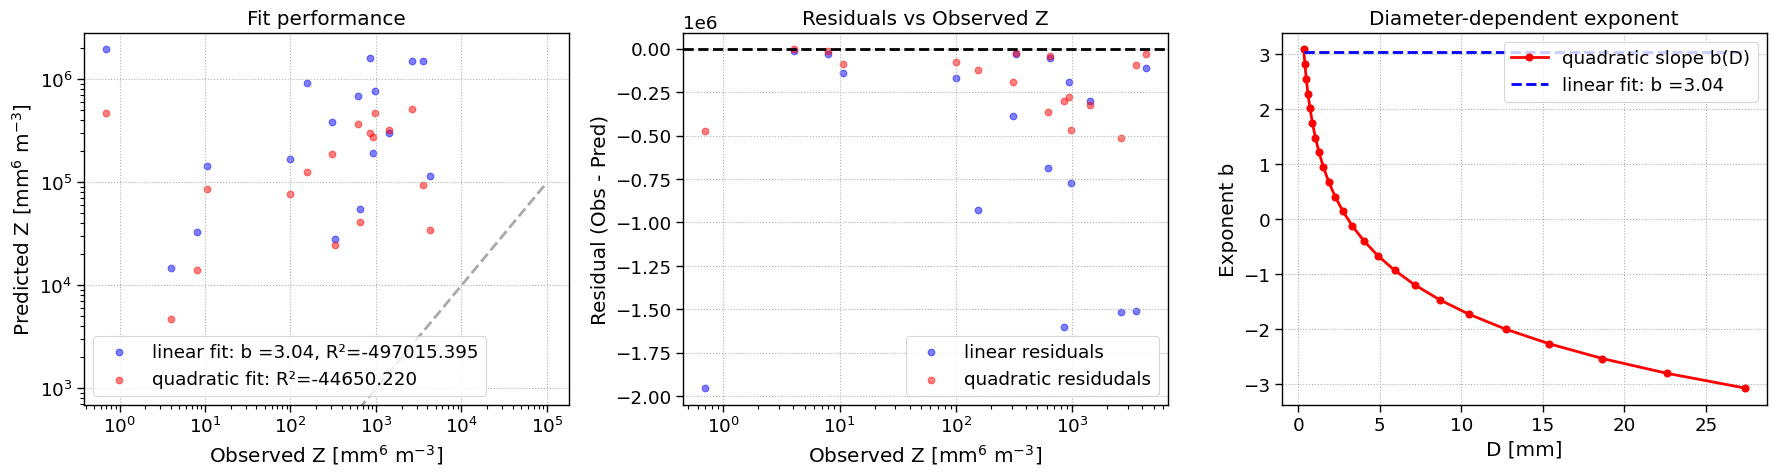

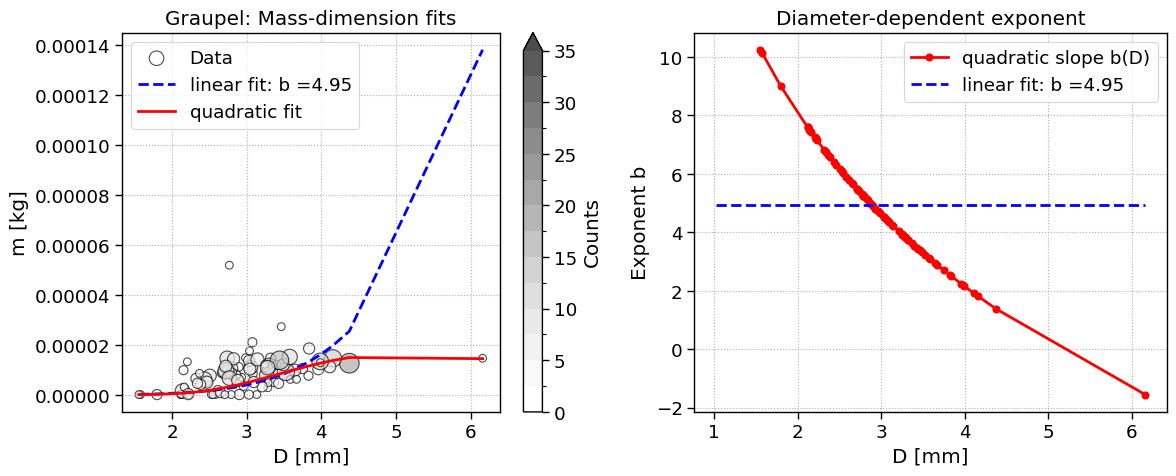

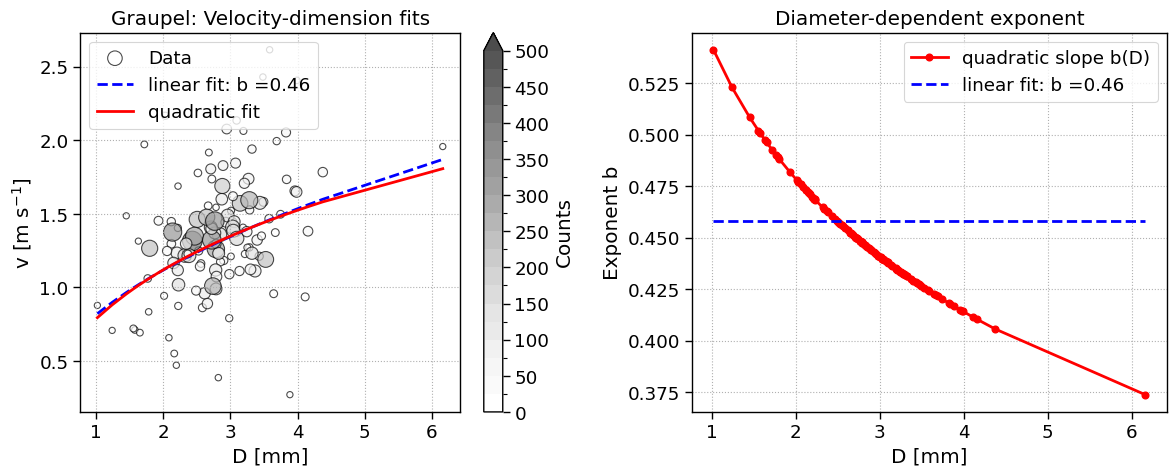

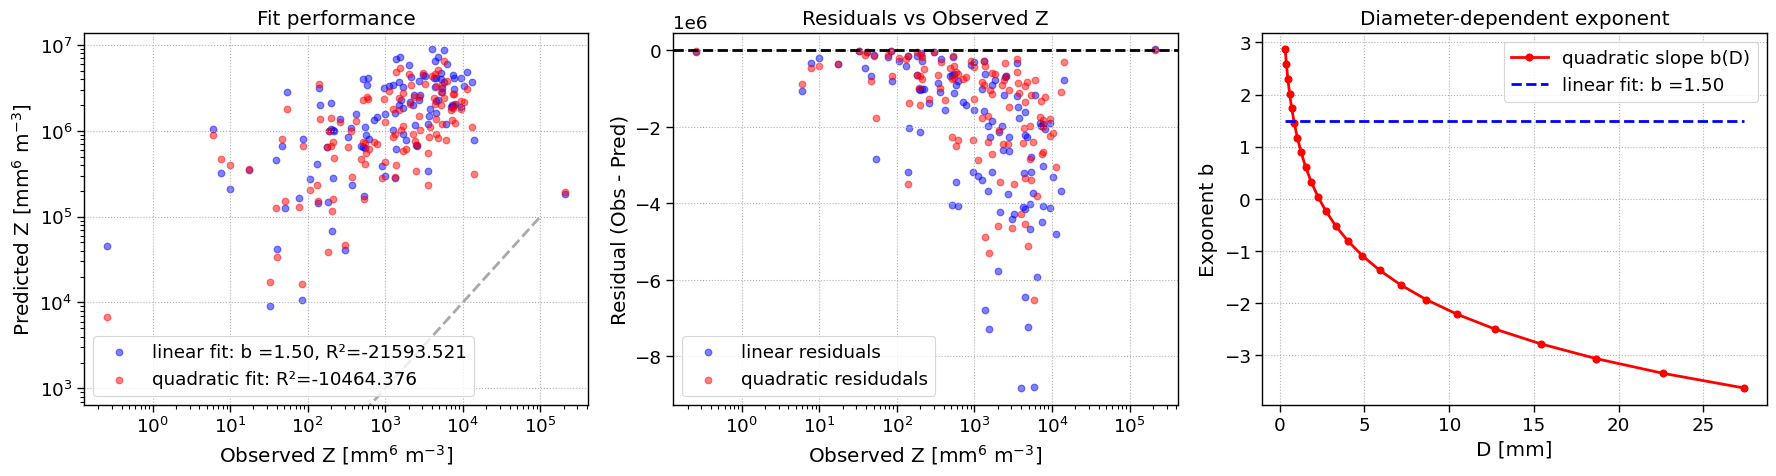

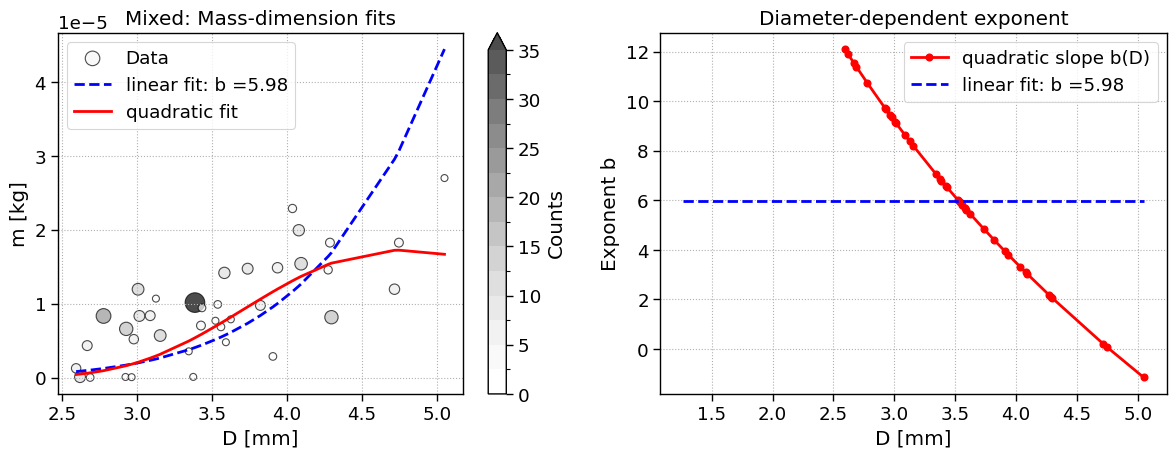

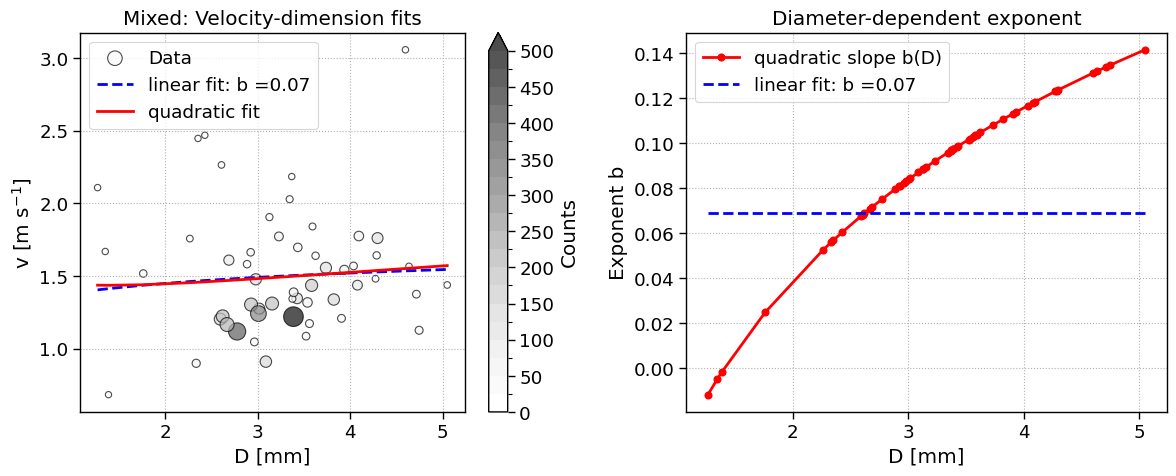

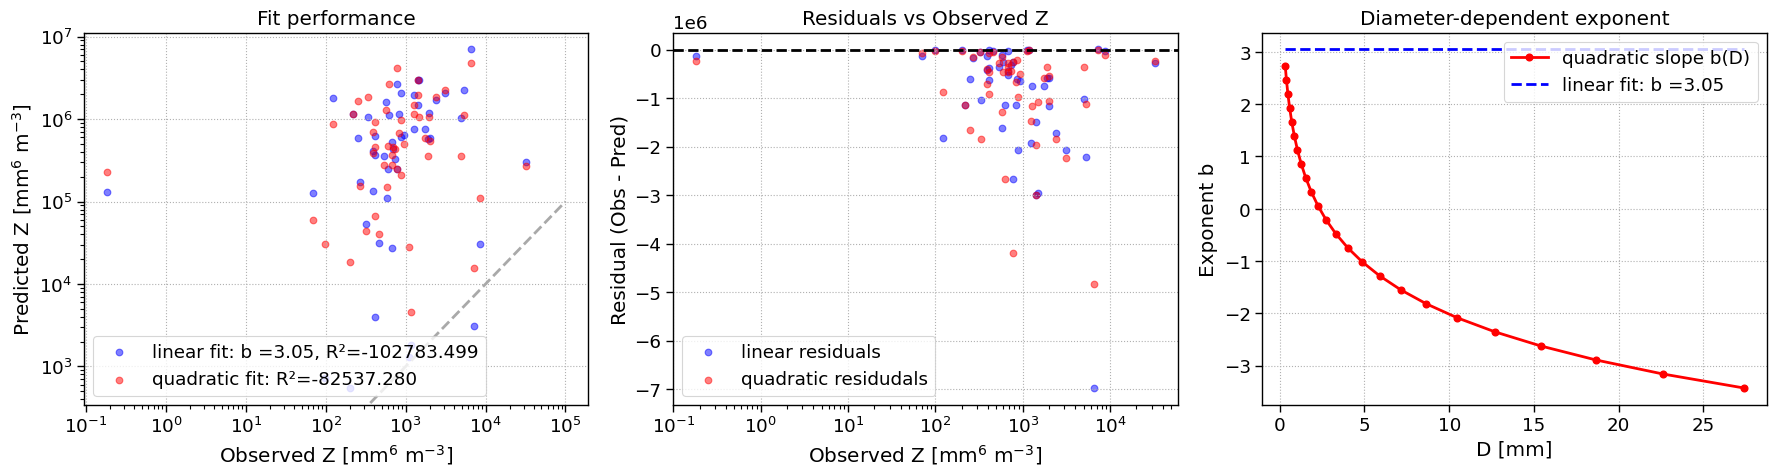

In [16]:
logD_sorted_m, log_lin_fit_m, log_quad_fit_m, b_local_m, b_lin_m = {}, {}, {}, {}, {}
logD_sorted_v, log_lin_fit_v, log_quad_fit_v, b_local_v, b_lin_v = {}, {}, {}, {}, {}
logD_sorted_s, log_lin_fit_s, log_quad_fit_s, b_local_s, b_lin_s, a_lin_s = {}, {}, {}, {}, {}, {}


for class_name in ['all', 'aggregate', 'graupel', 'mixed']:
    if class_name == 'all':
        _df = df['30min'].copy()
        _ds = (ds_psd['30min'].sel(time_frame='dt')).copy()
    else:
        _df = df['30min'][df['30min']['snowflake_class_name'] == class_name]#df_only_class[duration][class_name]
        _ds = fct.get_ds_in_precip_event(_df, (ds_psd['30min'].sel(time_frame='dt')))

    logD_sorted_m[class_name], log_lin_fit_m[class_name], log_quad_fit_m[class_name], b_local_m[class_name], b_lin_m[class_name] = fct.find_dimension_fits(_df, 'gan3d_mass')
    
    logD_sorted_v[class_name], log_lin_fit_v[class_name], log_quad_fit_v[class_name], b_local_v[class_name], b_lin_v[class_name] = fct.find_dimension_fits(_df, 'fallspeed')

    logD_sorted_s[class_name], log_lin_fit_s[class_name], log_quad_fit_s[class_name], b_local_s[class_name], b_lin_s[class_name], a_lin_s[class_name] = fct.find_dimension_fits_sigma(_df, _ds)

    fct.plt_dimension_fits(_df, variable='gan3d_mass', logD=logD_sorted_m[class_name], log_lin_fit=log_lin_fit_m[class_name], log_quad_fit=log_quad_fit_m[class_name], b_local=b_local_m[class_name], b_lin=b_lin_m[class_name], var_name=f'{class_name}: Mass'.title(), ylabel="m [kg]")

    fct.plt_dimension_fits(_df, variable='fallspeed', logD=logD_sorted_v[class_name], log_lin_fit=log_lin_fit_v[class_name], log_quad_fit=log_quad_fit_v[class_name], b_local=b_local_v[class_name], b_lin=b_lin_v[class_name], var_name=f'{class_name}: Velocity'.title(), ylabel="v [m s$^{-1}$]")

    fct.plt_residuals_dimension_fits(_ds, _df, log_quad_fit_s[class_name], b_local_s[class_name], a_lin_s[class_name], b_lin_s[class_name])

    
 

In [17]:
bzs = {}
for class_name in ['all', 'aggregate', 'graupel', 'mixed']:
    bzs[class_name] = (b_lin_s[class_name] + 1) / (b_lin_m[class_name] + b_lin_v[class_name] +1)
    print(f"{class_name}: bs={b_lin_s[class_name].round(2)}, bm={b_lin_m[class_name].round(2)}, bv={b_lin_v[class_name].round(2)}, bzs={bzs[class_name].round(2)}" )

all: bs=0.64, bm=3.91, bv=0.32, bzs=0.31
aggregate: bs=3.04, bm=1.91, bv=0.29, bzs=1.26
graupel: bs=1.5, bm=4.95, bv=0.46, bzs=0.39
mixed: bs=3.05, bm=5.98, bv=0.07, bzs=0.57


In [19]:
S_vals = (df['30min']['rate_mm_h'])
Z_vals = df['30min']['Ze_linear_sum_400']
dt = df['30min']['delta_h']

valid = (~np.isnan(S_vals)) & (~np.isnan(Z_vals))
Z_sel = Z_vals[valid]
S_sel = S_vals[valid]

# integrals in hours:
# numerator = np.nansum( (Z_sel **(1.0/bzs['all']))*dt[0])
# denominator = np.nansum( S_sel*dt[0])
azs = {}
for class_name in ['all', 'aggregate', 'graupel', 'mixed']:
    numerator = ((Z_sel**1/bzs[class_name])).resample('30Min').sum()
    denominator = (S_sel ).resample('30min').sum()

    a = (numerator/denominator)**bzs[class_name]
    azs[class_name] = a.mean()
    print(f"{class_name}: Z={azs[class_name].round(2)} S^{bzs[class_name].round(2)}")

all: Z=14.9 S^0.31
aggregate: Z=158266.98 S^1.26
graupel: Z=27.53 S^0.39
mixed: Z=126.17 S^0.57


In [143]:
S_sim = (1/azs['all'] * df['event_offset']['Ze_linear_sum_400'])**(1/bzs['all']) / df['event_offset']['delta_h']

In [144]:
S_sim

time
2023-02-19 08:27:00             NaN
2023-02-19 08:29:00    1.221979e+06
2023-02-19 08:33:00    8.026545e+04
2023-02-19 08:40:00    2.626437e+02
2023-02-19 09:24:00    3.491885e-05
                           ...     
2023-03-12 14:51:00    1.009179e+06
2023-03-12 20:43:00    3.427251e+06
2023-03-12 23:17:00    1.584986e+05
2023-03-13 01:07:00    2.283509e+05
2023-03-13 01:13:00    4.936427e+04
Length: 607, dtype: float64

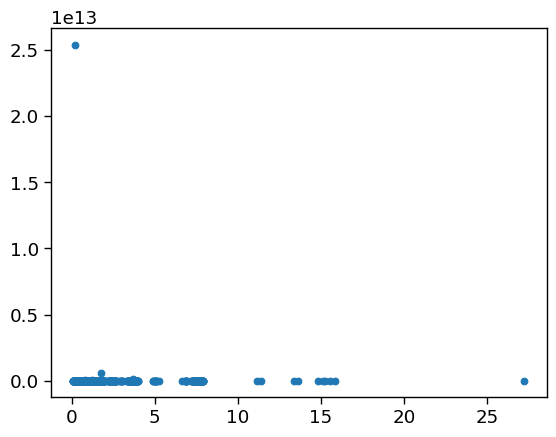

In [145]:
plt.scatter(df['event_offset']['rate_mm_h'], S_sim)

In [ ]:
# Log-linear regressions ln(y) = ln(a) + b*ln(x) --> gives a straight line
logx = (np.where(dsx_zs_1h["rate_mm_h"] >0, np.log(dsx_zs_1h["rate_mm_h"]), np.nan))#np.log(dsx_zs_1h["rate_mm_h"])
logy = (np.where(dsx_zs_1h['Ze_linear'] >0, np.log(dsx_zs_1h['Ze_linear']), np.nan)) #np.log(dsx_zs_1h["Ze_linear"])

# Drop rows where either logx or logy is Nan
valid = (~np.isnan(logx)) & (~np.isnan(logy))
logx_clean = logx[valid]
logy_clean = logy[valid]


# Linear regression on log-log data
b2, loga = np.polyfit(logx_clean, logy_clean, 1)
a2 = np.exp(loga)

print(f"Fit: Z = {a2:.3f} * S^{b2:.3f}")

# Nonlinear curve fitting 
# the curve fitting is done with an iterative nonlinear optimization. The optimizer starts at the guess p0, then tries to minimize the squared error between the model and the data. A good initial guess helps the optimizer converge quickly and to get the right solution. 
# From the log-linear regression we get a quick estimate of a and b, that's why we use those as p0
params, cov = curve_fit(model, dsx_zs_1h['rate_mm_h'], dsx_zs_1h['Ze_linear'], p0=(a2,b2))
a, b = params
print(f"Fit: Z = {a:.3f} * S^{b:.3f}")

In [ ]:
fig, ax = plt.subplots(figsize=(8,8))
ax.scatter(x=dsx_zs_1h['rate_mm_h'], y=dsx_zs_1h['Ze_linear'])

# Plot trend line non-linear
x_smooth = np.linspace(dsx_zs_1h['rate_mm_h'].min().values, dsx_zs_1h['Ze_linear'].max().values, 200)
y_smooth = model(x_smooth, a2, b2)
ax.plot(x_smooth, y_smooth, color='darkorange', label=f"ANX-2023 fit: Z = {a:.2f} * S$^{{{b:.3f}}}$")

# Generate line for Matrosov
xfit = np.linspace(df_corrected["Matrosov_aggregate"].min(), df_corrected["Ze_linear"].max(), 200)
yfit = model(xfit, 56, 1.2)
plt.plot(xfit, yfit, color='crimson', label="Matrasov agg.: Z = 56 S$^{1.2}$")

# Set labels and title
ax.set_xlabel('Geonor Snowfall Rate [mm/h]')
ax.set_ylabel("Ze [mm$^{6}$/m$^{3}$]")
ax.grid(True, ls=':')
ax.set_yscale('log')
ax.set_xscale('log')
ax.legend()

ax.set_xlim([10**(-4), 10**3])
ax.set_ylim([10**(-1), 10**5])

plt.tight_layout()


In [ ]:
df['Matrosov_changing_r'] = (meteo['Ze_linear'] / 34) ** (1/1.1)
df['Matrosov_increasing_m']  = (meteo['Ze_linear'] / 66) ** (1/1.2)
df['Matrosov_decreasing_m']  = (meteo['Ze_linear'] / 48) ** (1/1.2)
df['Matrosov_increasing_v']  = (meteo['Ze_linear'] / 46) ** (1/1.2)
df['Matrosov_decreasing_v']  = (meteo['Ze_linear'] / 67) ** (1/1.2)




### Sum the retrieved precipitation amount between the changes in precipitation at the Geonor


In [ ]:
# df[df.index.duplicated(keep=False)]

In [ ]:
from scipy.optimize import curve_fit

In [ ]:
df_zs = df[["rate_mm/h", "Ze_linear"]].dropna()

In [ ]:
# Log-linear regressions ln(y) = ln(a) + b*ln(x) --> gives a straight line
logx = np.log(df_zs["rate_mm/h"])
logy = np.log(df_zs["Ze_linear"])

# Linear regression on log-log data
b2, loga = np.polyfit(logx, logy, 1)
a2 = np.exp(loga)

print(f"Fit: Z = {a2:.3f} * S^{b2:.3f}")

In [ ]:
# Nonlinear curve fitting 
# the curve fitting is done with an iterative nonlinear optimization. The optimizer starts at the guess p0, then tries to minimize the squared error between the model and the data. A good initial guess helps the optimizer converge quickly and to get the right solution. 
# From the log-linear regression we get a quick estimate of a and b, that's why we use those as p0
params, cov = curve_fit(model, df_zs['rate_mm/h'], df_zs['Ze_linear'], p0=(36,0.5))
a, b = params
print(f"Fit: Z = {a:.3f} * S^{b:.3f}")

In [ ]:


fig, ax = plt.subplots(figsize=(8,8),)
ax.scatter(x=df['rate_mm/h'], y=df['Ze_linear'], color=cm.lipariS(2), alpha=0.7, marker='+', )


# # Create an array for the diagonal line
# diagonal_line = np.linspace(0, 100, 100)

# # Plot the diagonal line
# ax.plot(diagonal_line, diagonal_line, color='darkgrey', linestyle=':', )

# Plot trend line non-linear
# Generate smooth curve for plotting
x_smooth = np.linspace(df_zs['rate_mm/h'].min(), df_zs['Ze_linear'].max(), 200)
y_smooth = model(x_smooth, a, b)
plt.plot(x_smooth, y_smooth, color=cm.lipariS(2), label=f"Fit non-linear: Z = {a:.2f} * S^{b:.3f}")

# Plot log-linear regression
y_smooth = model(x_smooth, a2, b2)
plt.plot(x_smooth, y_smooth, color=cm.lipariS(0), label=f"Fit log-linear: Z = {a2:.2f} * S^{b2:.3f}")



# Generate line for Matrosov
xfit = np.linspace(df["Matrosov_aggregate"].min(), df["Ze_linear"].max(), 200)
yfit = model(xfit, 56, 1.2)
plt.plot(xfit, yfit, color=cm.lipariS(3), label="Matrasov agg. (Z = 56 S$^{1.2}$)")

xfit = np.linspace(df["Matrosov_changing_r"].min(), df["Ze_linear"].max(), 200)
yfit = model(xfit, 34, 1.1)
plt.plot(xfit, yfit, color=cm.lipariS(4), label="Matrasov changing r (Z = 34 S$^{1.1}$)")

xfit = np.linspace(df["Matrosov_increasing_m"].min(), df["Ze_linear"].max(), 200)
yfit = model(xfit, 66, 1.2)
plt.plot(xfit, yfit, color=cm.lipariS(5), label="Matrasov increasing m (Z = 66 S$^{1.2}$)")

xfit = np.linspace(df["Matrosov_decreasing_m"].min(), df["Ze_linear"].max(), 200)
yfit = model(xfit, 48, 1.2)
plt.plot(xfit, yfit, color=cm.lipariS(6), label="Matrasov increasing m (Z = 48 S$^{1.2}$)")

xfit = np.linspace(df["Matrosov_increasing_v"].min(), df["Ze_linear"].max(), 200)
yfit = model(xfit, 46, 1.2)
plt.plot(xfit, yfit, color=cm.lipariS(7), label="Matrasov increasing v (Z = 46 S$^{1.2}$)")

xfit = np.linspace(df["Matrosov_decreasing_v"].min(), df["Ze_linear"].max(), 200)
yfit = model(xfit, 67, 1.2)
plt.plot(xfit, yfit, color=cm.lipariS(8), label="Matrasov increasing m (Z = 67 S$^{1.2}$)")

# # Generate line for Bracci
# xfit = np.linspace(df["Bracci_aggregate"].min(), df["Ze_linear"].max(), 200)
# yfit = model(xfit, 134, 1.25)
# plt.plot(xfit, yfit, color=cm.lipariS(4), label="Bracci agg. (Z = 134 S$^{1.25}$)")

# # Generate line for Nakai
# xfit = np.linspace(df["Nakai_aggregate"].min(), df["Ze_linear"].max(), 200)
# yfit = model(xfit, 107.4, 1.67)
# plt.plot(xfit, yfit, color=cm.lipariS(5), label="Nakai agg. (Z = 107 S$^{1.67}$)")

# xfit = np.linspace(df["Nakai_graupel"].min(), df["Ze_linear"].max(), 200)
# yfit = model(xfit, 227.4, 1.67)
# plt.plot(xfit, yfit, color=cm.lipariS(6), label="Nakai grau. (Z = 227.4 S$^{1.67}$)")

# # Generate line for Pu
# xfit = np.linspace(df["Pu_graupel"].min(), df["Ze_linear"].max(), 200)
# yfit = model(xfit, 252, 2.03)
# plt.plot(xfit, yfit, color=cm.lipariS(7), label="Pu grau. (Z = 252 S$^{2.03}$)")

# Set labels and title
ax.set_xlabel('Geonor Snowfall Rate (mm h$^{-1}$)')
ax.set_ylabel("Reflectivity (mm$^{-6}$ m$^{-3}$)")
ax.set_title("Z-S relationship")# per Snowfall Class")
ax.legend()

ax.set_xlim(df['rate_mm/h'].min(), df['rate_mm/h'].max())
ax.set_ylim(df['Ze_linear'].min(), df['Ze_linear'].max())


ax.grid(True, ls=':')

# Ensure the aspect ratio is equal to make the 1:1 line truly diagonal
# ax.set_aspect('equal', adjustable='box')
ax.set_yscale('log')
ax.set_xscale('log')
plt.tight_layout()

figname = f"{FIG_DIR}/snowfall_rate/Z_S_relationship.png"
plt.savefig(figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

In [ ]:
10**2

In [ ]:
# df[(df["wind_direction"] < 157.5) | (df["wind_direction"] >= 202.5)]

In [ ]:
df[['Geonor','Matrosov_aggregate', 'Bracci_aggregate', 'Nakai_aggregate', 'Nakai_graupel', 'Pu_graupel']].cumsum().plot(grid=True, )

In [ ]:
precip_1h = df[["Geonor",	"Matrosov_aggregate",	"Bracci_aggregate",	"Nakai_aggregate",	"Nakai_graupel",	"Pu_graupel", "rate_mm/h"]].resample('1h').sum('time')

In [ ]:
# Fit a linear regression (y = m*x + b)
# m, b = np.polyfit(precip_1h['Geonor'], precip_1h['Matrosov_aggregate'], 2)

In [ ]:
# Fit a 2nd degree polynomial (quadratic)
coeffs = np.polyfit(precip_1h['Geonor'], precip_1h['Matrosov_aggregate'], 1)   # change "2" to 3 for cubic, etc.
poly_eq = np.poly1d(coeffs)

# Generate smooth x values for the curve
x_smooth = np.linspace(precip_1h['Geonor'].min(), precip_1h['Geonor'].max(), 200)
y_smooth = poly_eq(x_smooth)




In [ ]:
fig, ax = plt.subplots(figsize=(8,8),)
ax.scatter(x=precip_1h['Geonor'], y=precip_1h['Matrosov_aggregate'], color=cm.lipariS(2), alpha=0.7, marker='+', )#label='Aggregate')#s=30)

# Create an array for the diagonal line
diagonal_line = np.linspace(0, 4, 100)

# Plot the diagonal line
ax.plot(diagonal_line, diagonal_line, color='darkgrey', linestyle=':', )

# Plot trend line
# plt.plot(precip_1h['Geonor'], m*precip_1h['Geonor'] + b, color="red", label=f"Trend line (y={m:.2f}x+{b:.2f})")
plt.plot(x_smooth, y_smooth, color="red", label=f"Poly fit (deg=2)")


# Set labels and title
ax.set_xlabel('Precipitation Geonor (mm)')
ax.set_ylabel('Precipitation Matrosov (mm/h)')
ax.set_title("Surface Snowfall Rate")# per Snowfall Class")
# ax.legend()

# ax.set_xlim([-0.001,0.7])
# ax.set_ylim([-0.001,0.7])


ax.grid(True, ls=':')

# Ensure the aspect ratio is equal to make the 1:1 line truly diagonal
# ax.set_aspect('equal', adjustable='box')
ax.set_yscale('log')
ax.set_xscale('log')

In [ ]:
mask = dsx['most_common_class'] == ''
# select all rows except the ones that contain ''
most_common_class = dsx['most_common_class'].where(~mask)
most_common_class = most_common_class.dropna('time')

In [ ]:
precip_res['precipitation'].min()

In [ ]:
precip_res = precip_res.where(precip_res['precipitation'] >=0.002).dropna()

In [ ]:
fig, ax = plt.subplots(figsize=(8,8),)
ax.scatter(x=precip_res['precipitation'], y=precip_res['Matrosov_aggregate'], color=cm.lipariS(2), alpha=0.7, marker='+', )#label='Aggregate')#s=30)

# Create an array for the diagonal line
diagonal_line = np.linspace(0, 0.7, 100)

# Plot the diagonal line
ax.plot(diagonal_line, diagonal_line, color='darkgrey', linestyle=':', )

# Set labels and title
ax.set_xlabel('Precipitation Geonor (mm)')
ax.set_ylabel('Precipitation Matrosov (mm/h)')
ax.set_title("Surface Snowfall Rate per Snowfall Class")
# ax.legend()

ax.set_xlim([-0.001,0.7])
ax.set_ylim([-0.001,0.7])


ax.grid(True, ls=':')

# Ensure the aspect ratio is equal to make the 1:1 line truly diagonal
ax.set_aspect('equal', adjustable='box')
# ax.set_yscale('log')
# ax.set_xscale('log')

In [ ]:
precip_agg = (dsx['precipitation'].where((most_common_class == 'aggregate')))
matrosov_agg = (dsx['Matrosov_aggregate'].where((most_common_class == 'aggregate')))

precip_gra = (dsx['precipitation'].where((most_common_class == 'graupel')))
matrosov_gra = (dsx['Matrosov_aggregate'].where((most_common_class == 'graupel')))

precip_mix = (dsx['precipitation'].where((most_common_class == 'mixed')))
matrosov_mix = (dsx['Matrosov_aggregate'].where((most_common_class == 'mixed')))

fig, ax = plt.subplots(figsize=(8,7),)
ax.scatter(x=precip_agg, y=matrosov_agg, color=cm.lipariS(2), alpha=0.7, marker='+', label='Aggregate')#s=30)
ax.scatter(x=precip_gra, y=matrosov_gra, color=cm.lipariS(4), alpha=0.7, marker='+', label='Graupel')#s=30)
ax.scatter(x=precip_mix, y=matrosov_mix, color=cm.lipariS(3), alpha=0.7, marker='+', label='Mixed')#s=30)

# Create an array for the diagonal line
diagonal_line = np.linspace(0, 0.7, 100)

# Plot the diagonal line
ax.plot(diagonal_line, diagonal_line, color='darkgrey', linestyle=':', )

# Set labels and title
ax.set_xlabel('Precipitation Geonor (mm/h)')
ax.set_ylabel('Precipitation Matrosov (mm/h)')
ax.set_title("Surface Snowfall Rate per Snowfall Class")
ax.legend()

# ax.set_xlim([-0.001,0.7])
# ax.set_ylim([-0.001,0.7])


ax.grid(True, ls=':')

# Ensure the aspect ratio is equal to make the 1:1 line truly diagonal
# ax.set_aspect('equal', adjustable='box')
ax.set_yscale('log')
ax.set_xscale('log')

In [ ]:
dsx['most_common_class'].dropna(dim='time').values

In [ ]:
(dsx['precipitation'].where(dsx['most_common_class'] == 'graupel')).dropna(dim='time')

In [ ]:
# dsx['precipitation'], 
dsx['Matrosov_aggregate'].plot()

In [ ]:
# dsx['precipitation'].sel(time=slice('2023-02-16T05:00', '2023-02-16T06:00')).plot.scatter()

In [ ]:
dsx['precipitation'].dropna('time')

In [ ]:
plt.plot(dsx['precipitation'])

In [ ]:
dsx['precipitation'].plot.scatter(marker='o', edgecolor=None)

In [ ]:
dsx['air_temperature'].max().values

In [ ]:
dsx['precipitation'].cumsum().plot()
dsx['Matrosov_aggregate'].cumsum().plot()
dsx['Bracci_aggregate'].cumsum().plot()

In [ ]:

plt.scatter(x=dsx['precipitation'], y= dsx['Matrosov_aggregate'])
plt.yscale('log')
plt.xscale('log')

### previous seperation into "CAO", "WAI" and "undefined" was too complicated and led to inconsistency

- the clearest signal appears, when focusing on 
  - **southerly and southeasterly wind** (dominated by aggregate)
  - **southwest to east wind** (dominated by graupel)
  - alternative 
    - **southwest and westerly wind** (dominated by graupel >60%)
    - **northwesterly to easterly wind** (dominated by graupel >70%)

- Proposed simpler categorization
  - southerly/southeasterly flow (e.g. 112.5° - 202.5°): **aggregate** dominated &rarr; call this "WAI"
  - northwesterly/easterly flow (e.g. 0 - 112.5°, 292.5° - 360°): **graupel** dominated &rarr; call this "marine" or "CAO"
  - southwesterly/westerly flow (e.g. 202.5° - 292.5°): **somewhat graupel** dominated &rarr; call this "other"
  - keep it *based on WD only*, not temperature


In [ ]:
cao_wd_condition = ((dsx['wind_direction'] < 112.5) | 
                    # (dsx['wind_direction'] >= 202.5)).compute()
                    (dsx['wind_direction'] >= 292.5)).compute()

wai_wd_condition = ((dsx['wind_direction'] >= 112.5) & 
                    (dsx['wind_direction'] < 202.5)).compute()
    
other_wd_condition = ((dsx['wind_direction'] >= 202.5) &
                      (dsx['wind_direction'] < 292.5)).compute()


# Combine logical masks
cao_mask = cao_wd_condition #& cao_2t_condition
wai_mask = wai_wd_condition #& wai_2t_condition
other_mask = other_wd_condition
    
for var in var_names:
    if var in dsx:
        dsx[var+'_marine'] = dsx[var].where(cao_mask, drop=True)
        dsx[var+'_wai'] = dsx[var].where(wai_mask, drop=True)
        dsx[var+'_other'] = dsx[var].where(other_mask, drop=True)
        
        # print(f"{loc}, {var}, All: {dsx[var].count().values}, CAO: {dsx[var+'_marine'].count().values}, WAI: {dsx[var+'_wai'].count().values}, Undef: {dsx[var+'_other'].count().values}")
        print(f"{loc}, {var}, All: {dsx[var].count().values}, CAO: {dsx[var+'_marine'].count().values}, WAI: {dsx[var+'_wai'].count().values}")




### Use the empirical Ze-S relationship as given in 
Maahn, M. and Kollias, P.: Improved Micro Rain Radar snow measurements using Doppler spectra post-processing, Atmos. Meas. Tech., 5, 2661–2673, https://doi.org/10.5194/amt-5-2661-2012, 2012. 

$$ Ze = 56 \cdot S^{1.2}  \rightarrow S = \left(\frac{Ze}{56}\right)^{1/1.2}$$

assume Ze in $mm^6/m^3$ to get from [dBz] to [$mm^6/m^3$]

$$Ze [dBz] = 10 \cdot log_{10}(Ze [mm^6/m^3])$$
$$\rightarrow Ze [mm^6/m^3] = 10 ^{dBz/10}$$

In [ ]:
# Convert Ze (dBz) to snowfall rate (S)
def ze_to_snowfall_rate(Ze_dbz):
    # Ze to linear units
    Ze_lin = 10 ** (Ze_dbz /10)
    # Apply Z-S relationship
    S = (Ze_lin / 56) ** (1/1.2)                # Matrosov (2007) - aggregate snowflakes
    S_bracci = (Ze_lin / 134) ** (1/1.25)       # Bracci et al. (2021) - aggregate
    S_nakai_a = (Ze_lin / 107.4) ** (1/1.67)    # Nakai et al. (2021) - heavily rimed aggregate
    S_nakai_g = (Ze_lin / 227.4) ** (1/1.67)    # Nakai et al. (2021) - graupel
    S_pu = (Ze_lin / 252) ** (1/2.03)           # Pu et al. (2020) - graupel


    # convert rate per minute to mm/h
    S = (S/60).resample(time='1H').sum()
    S_bracci = (S_bracci/60).resample(time='1H').sum()
    S_nakai_a = (S_nakai_a/60).resample(time='1H').sum()
    S_nakai_g = (S_nakai_g/60).resample(time='1H').sum()
    S_pu = (S_pu/60).resample(time='1H').sum()
    
    df1 = S.isel(range=3).drop('range').rename('Matrosov_aggregate').to_dataframe()
    df2 = S_bracci.isel(range=3).drop('range').rename('Bracci_aggregate').to_dataframe()
    df3 = S_nakai_a.isel(range=3).drop('range').rename('Nakai_aggregate').to_dataframe()
    df4 = S_nakai_g.isel(range=3).drop('range').rename('Nakai_graupel').to_dataframe()
    df5 = S_pu.isel(range=3).drop('range').rename('Pu_graupel').to_dataframe()
    
    combined_df = pd.concat([df1, df2, df3, df4, df5], axis=1) # Use axis=1 to combine as new columns
    return  combined_df # in mm/hr


In [ ]:
ze = dsx['Ze']#.isel(range=3)
df_snowfall_rate = ze_to_snowfall_rate(ze)

In [ ]:
df_snowfall_rate['precip_gauge'] = dsx['precipitation'].dropna('time').to_series()

In [ ]:
# Get cummulative LWE
df_cumsum = df_snowfall_rate.loc["2023-02-17":].cumsum()

# set up figure
fig, ax = plt.subplots(figsize=(9,6))

# Get glasgow colors
n_lines = df_cumsum.shape[1] if df_cumsum.ndim > 1 else 1
colors = cm.glasgow(np.linspace(0,1,n_lines))

# Plot each column in colors
if df_cumsum.ndim > 1:
    for i, col in enumerate(df_cumsum.columns):
        ax.plot(df_cumsum.index, df_cumsum[col], color=colors[i], label=col, linewidth=1.8, alpha=0.7)
    ax.legend(title="Assumption", fontsize=9, title_fontsize=10, loc='upper left')
else: 
    ax.plot(df_cumsum.index, df_cumsum, color=colors[0], linewidth=1.8, alpha=0.7)
    
# Styling
ax.set_ylabel("Cumulative LWE", fontsize=12)
ax.set_xlabel("Date", fontsize=11)
ax.grid(True, linestyle=':')
ax.set_title("Cumulative Snowfall (LWE) between 2023-02-17 - 2023-03-14", fontsize=13)
ax.tick_params(axis='both', labelsize=10)
plt.tight_layout()

figname = f"snowfall_rate/cumsum_literature_values.png"
plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

In [ ]:
# Example: ranges based on literature or uncertainty bounds
a_vals = np.linspace(50, 100, 6)       # e.g. [50, 55, 60, 65, 70]
b_vals = np.linspace(1.1, 1.6, 6)     # e.g. [1.1, 1.15, 1.2, 1.25, 1.3]

In [ ]:
# Create meshgrid of all (a, b) combinations
a_grid, b_grid = np.meshgrid(a_vals, b_vals, indexing='ij')  # shape: (5, 5)

In [ ]:
# Broadcast Ze​ to match shape of ensemble
ze_surface = 10 ** (dsx['Ze'].isel(range=3) /10)
# Prepare empty array to hold ensemble output
S_ensemble = np.empty((len(a_vals), len(b_vals), len(ze_surface.time)))

# Compute snowfall rate for each (a, b) pair
for i, a in enumerate(a_vals):
    for j, b in enumerate(b_vals):
        S_ensemble[i, j, :] = (ze_surface / a) ** (1 / b)
        
# Convert to xarray DataArray for easy analysis

S_da = xr.DataArray(
    data = S_ensemble,
    dims = ['a', 'b', 'time'],
    coords = {
        'a': a_vals,
        'b': b_vals,
        'time': ze_surface.time
    },
    name='S_ensemble'
)

# Resample to hourly snowfall accumulations:

S_hourly = (S_da / 60).sel(time=slice("2023-02-17", "2023-03-17")).resample(time='1H').sum()   # mm/h -> mm per hour

In [ ]:
from imports import (ListedColormap) 

In [ ]:
# Extract time-sliced and cumulative sum
S = S_hourly.cumsum(dim='time')

# Get total number of ensemble members
a_vals = S.a.values
b_vals = S.b.values
n_a = S.sizes['a']
n_b = S.sizes['b']

# (a,b) label list
labels = [(a, b) for a in a_vals for b in b_vals]
n_members = n_a * n_b


# Create figure
fig, ax = plt.subplots(figsize=(12, 6))

# Get glasgow colormap
cmap = cm.glasgow
colors = cmap(np.linspace(0, 1, n_members))

# Plot each ensemble member with a unique color
# i = 0
# for a_idx in range(n_a):
#     for b_idx in range(n_b):
#         S_member = S.isel(a=a_idx, b=b_idx)
#         S_member.plot(ax=ax, color=colors[i], alpha=0.7, linewidth=1, add_legend=False)
#         i += 1
for i, (a, b) in enumerate(labels):
    S_member = S.sel(a=a, b=b)
    S_member.plot(ax=ax, color=colors[i], alpha=0.7, linewidth=1, add_legend=False)
df_snowfall_rate['precip_gauge'].loc["2023-02-17":].cumsum().plot(ax=ax, color='k', linewidth=1.5, )

cmap_discrete = ListedColormap(colors)
bounds = np.arange(n_members +1) - 0.5
norm = fct.BoundaryNorm(bounds, cmap_discrete.N)

sm = plt.cm.ScalarMappable(cmap=cmap_discrete, norm=norm)
cbar = plt.colorbar(sm, ax=ax, ticks=np.arange(n_members), spacing='proportional', orientation='vertical')

# Set tick labels to (a,b)
cbar.set_ticklabels([f'({a:.0f},{b:.2f})' for (a, b) in labels])
cbar.ax.tick_params(labelsize=8)
cbar.set_label("Ensemble Members (a, b)", fontsize=10)

# # Optional: Colorbar with index
# sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=0, vmax=n_members-1))
# cbar = plt.colorbar(sm, ax=ax, label='Ensemble Member Index')

# Prettify the plot
ax.set_title("Cumulative Sum of Ensemble Members", fontsize=14)
ax.set_ylabel("Cummulative LWE (mm)")
ax.grid(True, linestyle=':')
ax.set_xlabel("Time")
plt.tight_layout()

figname = f"snowfall_rate/cumsum_ensemble.png"
plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

In [ ]:
valid_times = dsx['precipitation_marine'].sel(time=slice("2023-02-17", "2023-03-17")).dropna('time').time
S_hourly_filtered = S_hourly.sel(time=valid_times)
S_hourly_filtered = S_hourly_filtered.cumsum(dim='time')

s_gauge_filtered = dsx['precipitation_marine'].sel(time=valid_times)
s_gauge_filtered = s_gauge_filtered.cumsum(dim='time')

# Get total number of ensemble members
a_vals = S.a.values
b_vals = S.b.values
n_a = S.sizes['a']
n_b = S.sizes['b']

# (a,b) label list
labels = [(a, b) for a in a_vals for b in b_vals]
n_members = n_a * n_b


# Create figure
fig, ax = plt.subplots(figsize=(12, 6))

# Get glasgow colormap
cmap = cm.glasgow
colors = cmap(np.linspace(0, 1, n_members))


for i, (a, b) in enumerate(labels):
    S_member = S_hourly_filtered.sel(a=a, b=b)
    S_member.plot(ax=ax, color=colors[i], alpha=0.7, linewidth=1, add_legend=False)
s_gauge_filtered.plot(ax=ax, color='k', linewidth=1.5, )

cmap_discrete = ListedColormap(colors)
bounds = np.arange(n_members +1) - 0.5
norm = fct.BoundaryNorm(bounds, cmap_discrete.N)

sm = plt.cm.ScalarMappable(cmap=cmap_discrete, norm=norm)
cbar = plt.colorbar(sm, ax=ax, ticks=np.arange(n_members), spacing='proportional', orientation='vertical')

# Set tick labels to (a,b)
cbar.set_ticklabels([f'({a:.0f},{b:.2f})' for (a, b) in labels])
cbar.ax.tick_params(labelsize=8)
cbar.set_label("Ensemble Members (a, b)", fontsize=10)

# # Optional: Colorbar with index
# sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=0, vmax=n_members-1))
# cbar = plt.colorbar(sm, ax=ax, label='Ensemble Member Index')

# Prettify the plot
ax.set_title("Cumulative Sum of Ensemble Members (Marine)", fontsize=14)
ax.set_ylabel("Cummulative LWE (mm)")
ax.grid(True, linestyle=':')
ax.set_xlabel("Time")
plt.tight_layout()

figname = f"snowfall_rate/cumsum_ensemble_marine.png"
plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

In [ ]:
valid_times = dsx['precipitation_wai'].sel(time=slice("2023-02-17", "2023-03-17")).dropna('time').time
S_hourly_filtered = S_hourly.sel(time=valid_times)
S_hourly_filtered = S_hourly_filtered.cumsum(dim='time')

s_gauge_filtered = dsx['precipitation_wai'].sel(time=valid_times)
s_gauge_filtered = s_gauge_filtered.cumsum(dim='time')

# Get total number of ensemble members
a_vals = S.a.values
b_vals = S.b.values
n_a = S.sizes['a']
n_b = S.sizes['b']

# (a,b) label list
labels = [(a, b) for a in a_vals for b in b_vals]
n_members = n_a * n_b


# Create figure
fig, ax = plt.subplots(figsize=(12, 6))

# Get glasgow colormap
cmap = cm.glasgow
colors = cmap(np.linspace(0, 1, n_members))


for i, (a, b) in enumerate(labels):
    S_member = S_hourly_filtered.sel(a=a, b=b)
    S_member.plot(ax=ax, color=colors[i], alpha=0.7, linewidth=1, add_legend=False)
s_gauge_filtered.plot(ax=ax, color='k', linewidth=1.5, )

cmap_discrete = ListedColormap(colors)
bounds = np.arange(n_members +1) - 0.5
norm = fct.BoundaryNorm(bounds, cmap_discrete.N)

sm = plt.cm.ScalarMappable(cmap=cmap_discrete, norm=norm)
cbar = plt.colorbar(sm, ax=ax, ticks=np.arange(n_members), spacing='proportional', orientation='vertical')

# Set tick labels to (a,b)
cbar.set_ticklabels([f'({a:.0f},{b:.2f})' for (a, b) in labels])
cbar.ax.tick_params(labelsize=8)
cbar.set_label("Ensemble Members (a, b)", fontsize=10)

# # Optional: Colorbar with index
# sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=0, vmax=n_members-1))
# cbar = plt.colorbar(sm, ax=ax, label='Ensemble Member Index')

# Prettify the plot
ax.set_title("Cumulative Sum of Ensemble Members (WAI)", fontsize=14)
ax.set_ylabel("Cummulative LWE (mm)")
ax.grid(True, linestyle=':')
ax.set_xlabel("Time")
plt.tight_layout()

figname = f"snowfall_rate/cumsum_ensemble_wai.png"
plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

In [ ]:
valid_times = dsx['precipitation_other'].sel(time=slice("2023-02-17", "2023-03-17")).dropna('time').time
S_hourly_filtered = S_hourly.sel(time=valid_times)
S_hourly_filtered = S_hourly_filtered.cumsum(dim='time')

s_gauge_filtered = dsx['precipitation_other'].sel(time=valid_times)
s_gauge_filtered = s_gauge_filtered.cumsum(dim='time')

# Get total number of ensemble members
a_vals = S.a.values
b_vals = S.b.values
n_a = S.sizes['a']
n_b = S.sizes['b']

# (a,b) label list
labels = [(a, b) for a in a_vals for b in b_vals]
n_members = n_a * n_b


# Create figure
fig, ax = plt.subplots(figsize=(12, 6))

# Get glasgow colormap
cmap = cm.glasgow
colors = cmap(np.linspace(0, 1, n_members))


for i, (a, b) in enumerate(labels):
    S_member = S_hourly_filtered.sel(a=a, b=b)
    S_member.plot(ax=ax, color=colors[i], alpha=0.7, linewidth=1, add_legend=False)
s_gauge_filtered.plot(ax=ax, color='k', linewidth=1.5, )

cmap_discrete = ListedColormap(colors)
bounds = np.arange(n_members +1) - 0.5
norm = fct.BoundaryNorm(bounds, cmap_discrete.N)

sm = plt.cm.ScalarMappable(cmap=cmap_discrete, norm=norm)
cbar = plt.colorbar(sm, ax=ax, ticks=np.arange(n_members), spacing='proportional', orientation='vertical')

# Set tick labels to (a,b)
cbar.set_ticklabels([f'({a:.0f},{b:.2f})' for (a, b) in labels])
cbar.ax.tick_params(labelsize=8)
cbar.set_label("Ensemble Members (a, b)", fontsize=10)

# # Optional: Colorbar with index
# sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=0, vmax=n_members-1))
# cbar = plt.colorbar(sm, ax=ax, label='Ensemble Member Index')

# Prettify the plot
ax.set_title("Cumulative Sum of Ensemble Members (Other)", fontsize=14)
ax.set_ylabel("Cummulative LWE (mm)")
ax.grid(True, linestyle=':')
ax.set_xlabel("Time")
plt.tight_layout()

figname = f"snowfall_rate/cumsum_ensemble_other.png"
plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

In [ ]:
# Assume surface is the 3. lowest range gate
fig, ax = plt.subplots(figsize=(8,6), )
# Get glasgow colors
n_lines = df_snowfall_rate.shape[1] if df_snowfall_rate.ndim > 1 else 1
colors = cm.glasgow(np.linspace(0,1,n_lines))

if df_snowfall_rate.ndim > 1:
    for i, col in enumerate(df_snowfall_rate.columns):
        ax.scatter(df_snowfall_rate['precip_gauge'], df_snowfall_rate[col], color=colors[i], label=col, alpha=0.8, s=10)
    ax.legend(title="Assumption", fontsize=9, title_fontsize=10, loc='upper left')
else: 
    ax.scatter(df_snowfall_rate['precip_gauge'], df_snowfall_rate, color=colors[0], alpha=0.8, s=10)

# Labels, legend, grid
ax.set_ylabel("Snowfall Rate (mm/h)")
ax.set_xlabel("Snowfall Rate Precipitation Gauge (mm/h)")
ax.grid(True, ls=':')
ax.set_title("Surface Snowfall Rate per Assumption")

plt.tight_layout()

### Fit $Ze=a \cdot S ^b$

In [ ]:
for i in dsx['range'].values:
    plt.scatter(dsx['Z'].sel(range=i), snowfall_rate.sel(range=i))